# [1] 05 Validation against the USGS creepmeters, and the aperture choice

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. The bootstraps take ~2 min; the ladder scoring reads
the frozen sweep directories and takes ~1 min.
```

**What this notebook does.** It compares the InSAR creep with the five USGS
creepmeters over the same window, three ways (Methods M4):

- **creepmeter**: the instrument's own rate (ground truth, already fault-parallel)
- **crossing**: the InSAR fault-parallel creep rate from `fp_ts.csv` (notebook 03),
  a stack of up to 5 crossings next to the instrument, the narrow-aperture
  like-for-like match to a point instrument
- **step**: the fault-crossing step in the fault-parallel velocity field
  (notebook 02 transects, +/-1000 m), which also carries the distributed part

Every rate uncertainty is a moving-block bootstrap 95% confidence interval
(blocks of ~1 yr in time, ~100 m in distance), because both the time series
and the profiles are autocorrelated and an ordinary standard error would be
2 to 3 times too small. The detrended comparison gives the transient noise
floor that the event detector (notebook 04) works against.

It then measures the slip CFW1 recorded across each Tule Pond InSAR onset
window (from the raw 10-minute record), the number the text quotes for
whether the instrument at the south end of the section saw the events, and
checks every InSAR onset window (Tule Pond against CFW1, Oakland against
COZ1) against the published creepmeter event catalogue of Gittins et al.
(2026). The catalogue is used for TIMING only (Dani 2026-10-05: its
amplitude score, InSAR step / catalogued slip, is retired). The transient
amplitude is notebook 04's joint-model COZ1 steps against the creepmeter's,
read from 04's `creep_events.csv` and registered here as a recovery
percentage.

The second part draws the **aperture ladder**: why the creep time series use
the 30 to 150 m bin. The sweep itself was run once in July/August 2026; its
outputs (`sweep_summary_mp5.csv` and one `fp_ts.csv` per bin) are read here
as frozen inputs, fingerprinted in the registry, and re-scored on a fixed
stack. It is not re-run (Dani, 2026-09-21).
PREPUB: The sweep script is `Hayward_DISP-S1/analysis/run11b_sweep_ladder.py`.
PREPUB: Ported from `Hayward_DISP-S1/analysis/run10_creepmeter_validation.py`,
PREPUB: `plotting/fig_validation.py` and `plotting/figS_binning_ladder.py`.

**Inputs**: `03_creep_timeseries/fp_ts.csv`; the notebook 02 transects
(`fp_velocity_xfault_swath200m_dist1000m.csv`) and `fp_velocity_map.h5`;
`04_event_detection/creep_events.csv` (the onset windows `onset_lo` to
`onset_hi` of the Tule Pond and Oakland events, and the joint-model COZ1
amplitudes with the creepmeter steps) and `section_lengths.csv`; the
fault trace; the five creepmeter records; the digital catalogue of creepmeter
slip events of Gittins et al. (2026, Seismica 5(2), v1.0.0, ends December
2023; `common_paths["gittins_catalogue"]`); the frozen sweep (above).

**Outputs** (`outputs/05_validation/`): `station_agreement.csv`,
`gittins_comparison.csv`, `cfw1_gittins_near_windows.csv` (every CFW1
catalogue event near a Tule Pond InSAR window, the source of the catalogue
table in the text), `sweep_ladder_scores.csv`, `05_validation_stats.txt`,
registry rows `05_*`.

**Figures** (in the dated figure folder, .png and .pdf):
`figS_validation_cohmap<coh>_<params>_profile1000m_stack5x200m` (the five
stations, supplement, 600 dpi), `figS_binning_ladder_coh0.9_mp5_stack4x0.4km`
(the aperture ladder, supplement) and `qc05_creepmeter_glitches.png` (QC:
the listed creepmeter glitch days).

**What to check.** CFW1, CTM1 and CPP1 should agree with the creepmeters to a
few tenths of a millimetre a year; COZ1 is the known low outlier (the InSAR
recovers only part of its two large creep events); CHP1 runs high because
its creep is distributed over ~300 m. The detrended RMSE per station (~1.5 to
1.9 mm, mean ~1.7) is the noise floor of a stack of up to 5 crossings, the
number quoted in the text. CFW1 should show little slip across the Tule Pond
windows (well under the 7 to 11 mm InSAR steps). Both Oakland windows should
hold a catalogued COZ1 event (Gittins et al. 2026). The joint model of
notebook 04 recovers about 60% of the two COZ1 creepmeter steps. Only the listed
creepmeter glitch days are dropped (CPP1, two days; QC figure
`qc05_creepmeter_glitches`), and the COZ1 creep steps are as they were
(asserted).

In [1]:
# [2]
import os
import textwrap
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, creepmeters, params, x_width,
                                dist_min, dist_max, coh_timeseries, min_points, coh_velocity,
                                creepmeter_glitches, gittins_window_pad_days,
                                paths_out, repo_dir)

import numpy as np
import pandas as pd
import h5py
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pygmt

## [3] Paths and parameters

Every number the notebook uses, with what it is. The aperture-ladder bins are
listed here so their frozen sweep files can be fingerprinted before anything
is read.

In [2]:
# [4]
notebook = "05_validation"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# bootstraps
block_years = 1.0     # moving-block length for the time bootstraps (carries the annual cycle)
block_m = 100.0       # moving-block length (m) for the spatial step bootstrap
nboot = 2000          # bootstrap resamples
seed = 0

# the creepmeter glitch days (an explicit list, no automatic filter) and the widening of the Tule Pond windows for the
# CFW1 catalogue table are shared parameters in TulePond_filepaths: creepmeter_glitches, gittins_window_pad_days
step_check_mm = 0.1   # dropping the glitch days must leave every catalogued creep step on the daily record within this (asserted)
qc_half_days = 15     # QC figure: days shown either side of each glitch

# the InSAR stack at a creepmeter. fp_ts is indexed by LATITUDE, so these half-widths are applied
# as km / 111.19 deg of latitude (about 1.15 km along this oblique strike per km of latitude)
stack_km = 0.2        # half-window of fp_ts rows to stack at a creepmeter (matches the 400 m swath)
stack_widen_km = 1.0  # widen to this if the 0.2 km window has < 2 usable rows (CPP1 at the frame edge)
stack_max = 5         # cap the stack at the N nearest usable rows

# the notebook 02 transects
swath_m = 200.0       # swath half-width (m)
max_dist_m = 1000.0   # transect half-length (m)

# the map panel
strike = 144.0             # page rotation of the map panel (mean strike, notebook 02); its extent is utils.fault_map_corners (as Fig 1A)
ref_patch_km = 5.0         # map display reference: CTM1-COZ1 patch, +/- this across the fault
fp_clim = 5.0              # map colour range +/- this (mm/yr); the detrended panels span +/- 1.5 x this (mm)
prof_ylim = 7.0            # cross-fault profile panels: y range +/- this (mm/yr)

# the figure layout (cm): 18.3 cm wide after crop (Science full page width)
fig_width_cm = 18.1        # page width before crop; the label overhang brings it to <= 18.3 cm
row_height_cm = 2.1        # one row per creepmeter
gap_row_cm = 0.35          # between rows (the interior rows carry no x annotation)
map_axis_cm = 0.9          # room left of the map for its distance axis and label (fault_map_panel draws it outside the map)
gap_map_cm = 0.9           # between the map and the first data column
gap_col_cm = 0.6           # between the data columns
annot_offset_cm = 0.1      # B-F: the 'Velocity step' annotation's baseline sits this far above the bottom frame (and in from the right)
legend_clearance_cm = 0.02 # G-K: the legend box's padding above and below its text (GMT's default 4p would lift the text above the annotation)
legend_baseline_cm = 0.04  # G-K: GMT puts a legend line's baseline this far above the bottom of its line cell at 6.5p Helvetica
                           # (measured 2026-10-05 on a 600 dpi test: the descenders end on the cell bottom, ~0.04 cm below the baseline)
# so the BOTTOM line of each G-K legend is on the baseline of the B-F annotation: box bottom = annotation baseline - padding - baseline height
legend_offset_cm = annot_offset_cm - legend_clearance_cm - legend_baseline_cm
assert legend_offset_cm >= 0, f"the G-K legend box would hang below the panel frame ({legend_offset_cm:.2f} cm)"
cm_blue = "#0072B2"        # Okabe-Ito blue: the creepmeters
insar_grey = "gray55"      # the InSAR
onset_orange = "#E69F00"   # Okabe-Ito orange, long-dashed 0.9 pt: the InSAR onsets, the colour of Fig 3A's InSAR detection lines (notebook 11)

# the step across an event window ([8], event_step): the creepmeter glitch check of [14b] and the aperture
# ladder, which scores how much of the COZ1 creepmeter's step each aperture recovers (ladder panel D) across
# the two Oakland InSAR onset windows of notebook 04 (read in [12])
collar_yr = 0.75      # inter-event collar each side of a window for the local trend
min_collar_epochs = 5   # an event is scored only with this many epochs in each collar ...
min_fit_epochs = 12     # ... and this many finite epochs in the two collars together

# CFW1 vs the Tule Pond InSAR events (the instrument sits at the south end of the section). This notebook
# only MEASURES the creepmeter slip across each InSAR onset window, from the raw record and aware of
# its gaps; whether CFW1 (or COZ1) recorded a creep event is read from the published catalogue of
# Gittins et al. (2026) in [14], not from a detector written here.
cfw_edge_hours = 12   # slip across a window = median of the samples in the last 12 h before it closes minus
                      # the median in the first 12 h after it opens (nearest available samples if those are in a gap)
min_edge_samples = 6  # an edge needs this many 10-minute samples (1 h of data)
edge_search_days = 5  # if the edge is in a gap, use the nearest data within this many days
cfw1_insar_half_km = 0.2   # the InSAR step AT CFW1 ([14b]): mean of 04's per-crossing steps within +/- this ALONG THE TRACE
                           # of CFW1; its noise from the same mean at the two COZ1 events in independent windows of
                           # 2 x this along the Tule Pond section, where those events put no slip
noise_n_trials = 40        # [14b2]: the noise of a single-interval step at CFW1 = std of the CFW1 mean step at this many trial epochs,
noise_seed = 20261005      # drawn with this seed from the acquisition intervals at least
noise_clear_days = 60      # this far from every 04 onset window and every CFW1 catalogue event of at least
noise_gittins_min_mm = 0.3 # this slip (start to end), and from both ends of the record

# the ladder: bins scored on a FIXED stack (4 rows within 0.4 km, no widening)
# so every bin averages the same number of rows. The sweep was run at coherence
# 0.9; the three-threshold comparison of the chosen bin (below) is what justifies
# running the paper's stream at 0.7.
ladder_coh = 0.9
ladder_stack_km = 0.4
ladder_n_stack = 4
fixed_width = [(0, 100), (50, 150), (100, 200), (150, 250), (200, 300), (300, 400), (400, 500)]
growing = [(100, 200), (100, 300), (100, 400), (100, 500), (100, 700)]
original = [(0, 60), (30, 90), (60, 120), (0, 120), (30, 150), (60, 180), (200, 600), (500, 700)]
inner_edge = [(0, 150), (10, 150), (20, 150), (30, 150), (40, 150), (50, 150), (60, 150), (70, 150), (80, 150)]
selected = (int(dist_min * 1000), int(dist_max * 1000))      # the bin the paper uses
kernel_m = (55, 65)   # measured DISP-S1 phase-linking half-width, before / after the 2024-25 reprocessing

# every bin once, in the order of the four sets (a bin already in an earlier set is not repeated)
ladder_bins = []          # (set name, inner m, outer m)
already_listed = []
for set_name, bins in (("fixed", fixed_width), ("growing", growing), ("original", original), ("inner", inner_edge)):
    for inner, outer in bins:
        if (inner, outer) in already_listed:
            continue
        already_listed.append((inner, outer))
        ladder_bins.append((set_name, inner, outer))

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
xf_file = os.path.join(paths_out["02_velocity_decomposition"], f"fp_velocity_xfault_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.csv")
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")   # the measured section extents
event_steps_file = os.path.join(paths_out["04_event_detection"], "event_fraction_by_crossing.csv")   # 04's per-crossing joint-model steps
sweep_summary_file = os.path.join(common_paths["sweep_dir"], "sweep_summary_mp5.csv")

# the frozen sweep files this notebook reads: one fp_ts.csv per ladder bin, and the chosen bin at each coherence
sweep_fp_files = []
for set_name, inner, outer in ladder_bins:
    sweep_tag = f"ap{inner}-{outer}m_coh{ladder_coh:g}_mp{min_points}"
    assert os.path.isdir(os.path.join(common_paths["sweep_dir"], sweep_tag)), f"frozen sweep bin missing: {sweep_tag}"
    sweep_fp_files.append(os.path.join(common_paths["sweep_dir"], sweep_tag, "fp_ts.csv"))
sweep_summary = pd.read_csv(sweep_summary_file)
selected_by_coh = sweep_summary[sweep_summary.tag.str.startswith(f"ap{selected[0]}-{selected[1]}m")].sort_values("coh")
for sweep_tag in selected_by_coh.tag:
    sweep_fp_file = os.path.join(common_paths["sweep_dir"], sweep_tag, "fp_ts.csv")
    if sweep_fp_file not in sweep_fp_files:
        sweep_fp_files.append(sweep_fp_file)

creepmeter_files = []
for code, lat, lon, name in creepmeters:
    creepmeter_files.append(utils.creepmeter_file(common_paths["creepmeter_dir"], code))

REG = utils.Registry(notebook, common_paths, repo_dir)
track_files = [os.path.join(paths_out["03_creep_timeseries"], f"creep_ts_LOS_{track}.csv") for track in ("ascending", "descending")]
REG.inputs(fp_ts_file, xf_file, map_file, lengths_file, events_file, event_steps_file, *track_files, common_paths["fault_profiles"],
           *creepmeter_files, common_paths["gittins_catalogue"], sweep_summary_file, *sweep_fp_files)

Registry for 05_validation: run 29f818ee, git 940efd4+


## [5] LOAD: the creep time series, the transects and the creepmeters

The creepmeter records are daily means over the InSAR window with the
listed glitch days dropped (`utils.daily_creepmeter` with
`creepmeter_glitches` of TulePond_filepaths: instrument, first and last day,
reason; found by inspection, no automatic filter). Over this window only two
CPP1 days are glitches, each a 10-minute sample or two at -283.7 mm that
pulls the daily mean down by 2.4 and 4.8 mm. (The whole-record cut at 6
robust sigma + 10 mm it replaces dropped no day here and let both through.)
The days dropped are printed and drawn in [6b]. The InSAR
"stack" at a creepmeter is the mean of the nearest usable `fp_ts` rows within
0.2 km of latitude (about 230 m along strike), up to 5 rows, which is the
like-for-like match to the 400 m transect swath. Where fewer than 2 rows are
usable it widens to 1 km of latitude; the printout says which station did.

In [3]:
# [6]
def read_fp_ts(path):
    """A fault-parallel time-series table (notebook 03 layout): latitude x decimal year, mm."""
    table = pd.read_csv(path, index_col=0)
    table.columns = table.columns.astype(float)
    table.index = table.index.astype(float)
    return table


def stack_insar(fp_table, lat, half_km=stack_km, widen_km=stack_widen_km, n_stack=stack_max, exact=False):
    """Mean +/- std of the fp_ts rows nearest `lat` (rows with > 50% finite epochs, at most n_stack, nearest
    first). The rows are taken within half_km of latitude; if fewer than 2 are usable the window widens to
    widen_km. `exact=True` (the ladder) requires n_stack usable rows inside half_km and never widens, so
    every bin is scored on the same number of rows.
    Returns (dates, mean, std, n_rows, half-width used in km), or None if no stack can be formed."""
    n_epochs = fp_table.shape[1]
    if exact:
        half_widths_km = [half_km]
    else:
        half_widths_km = [half_km, widen_km]
    for half_width_km in half_widths_km:
        half_width_deg = half_width_km / 111.19                 # fp_ts is indexed by latitude
        nearby = fp_table[(fp_table.index >= lat - half_width_deg) & (fp_table.index <= lat + half_width_deg)]
        usable = nearby[nearby.notna().sum(axis=1) > 0.5 * n_epochs]
        if len(usable) >= 2:
            break
    if len(usable) == 0:
        return None
    if exact and len(usable) < n_stack:
        return None
    nearest_first = np.argsort(np.abs(usable.index.values - lat))
    usable = usable.iloc[nearest_first[:n_stack]]
    stack_dates = fp_table.columns.values.astype(float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack_mean = np.nanmean(usable.values, axis=0)
        stack_std = np.nanstd(usable.values, axis=0)
    return stack_dates, stack_mean, stack_std, len(usable), half_width_km


fp_ts = read_fp_ts(fp_ts_file)
t0 = float(fp_ts.columns.min())
t1 = float(fp_ts.columns.max())
xf = pd.read_csv(xf_file)
print(f"fp_ts: {fp_ts.shape[0]} crossings x {fp_ts.shape[1]} epochs, window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr)")
print(f"transects: {len(xf)} pixels at {xf.code.nunique()} creepmeters")

cm_data = {}
insar_stacks = {}
for code, lat, lon, name in creepmeters:
    cm_data[code] = utils.daily_creepmeter(common_paths["creepmeter_dir"], code, t0, t1, creepmeter_glitches)
    stacked = stack_insar(fp_ts, lat)
    assert stacked is not None, f"{code}: no usable fp_ts rows within {stack_widen_km} km of latitude"
    insar_stacks[code] = stacked
    cm_dates, cm_slip = cm_data[code]
    n_rows = stacked[3]
    half_width_used_km = stacked[4]
    if half_width_used_km == stack_km:
        widened_note = ""
    else:
        widened_note = f" (widened to {half_width_used_km:g} km of latitude)"
    print(f"  {code} ({name}): creepmeter {len(cm_dates)} days, {cm_slip[-1]:.1f} mm total; "
          f"InSAR stack of {n_rows} rows{widened_note}")

fp_ts: 611 crossings x 439 epochs, window 2016.672 to 2026.216 (9.54 yr)
transects: 3621 pixels at 5 creepmeters


  CPP1: 2 listed glitch days dropped of 3420: 2017-05-19 to 2017-05-19 (1 d: two 10-min samples at -283.7 mm (~340 mm below the record) pull the daily mean down 4.8 mm); 2018-02-13 to 2018-02-13 (1 d: one 10-min sample at -283.7 mm (~350 mm below the record) pulls the daily mean down 2.4 mm)
  CPP1 (Pinole Point): creepmeter 3418 days, 48.8 mm total; InSAR stack of 4 rows


  CTM1: 0 listed glitch days dropped of 3225
  CTM1 (Temescal): creepmeter 3225 days, 39.9 mm total; InSAR stack of 5 rows


  COZ1: 0 listed glitch days dropped of 3484
  COZ1 (Oakland Zoo): creepmeter 3484 days, 39.8 mm total; InSAR stack of 5 rows


  CHP1: 0 listed glitch days dropped of 3353
  CHP1 (Palisade Street): creepmeter 3353 days, 37.2 mm total; InSAR stack of 5 rows


  CFW1: 0 listed glitch days dropped of 3437
  CFW1 (Fremont): creepmeter 3437 days, 67.2 mm total; InSAR stack of 5 rows


## [6b] QC: the listed creepmeter glitch days, and two dips that are not glitches

One panel per listed glitch (`creepmeter_glitches`): the daily means as read
(vermillion; the dropped day marked) against the record kept (blue),
`qc_half_days` either side. The last two panels are the dips the author
asked about that are NOT creepmeter glitches: CTM1 around 2025.3 and CHP1 in
October 2021. The creepmeter (blue) is smooth there; the dip is one InSAR
epoch of the station stack (grey, shifted onto the creepmeter for display).
The figure `qc05_creepmeter_glitches.png` (QC, not in the paper).

Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-03_final/qc05_creepmeter_glitches.png


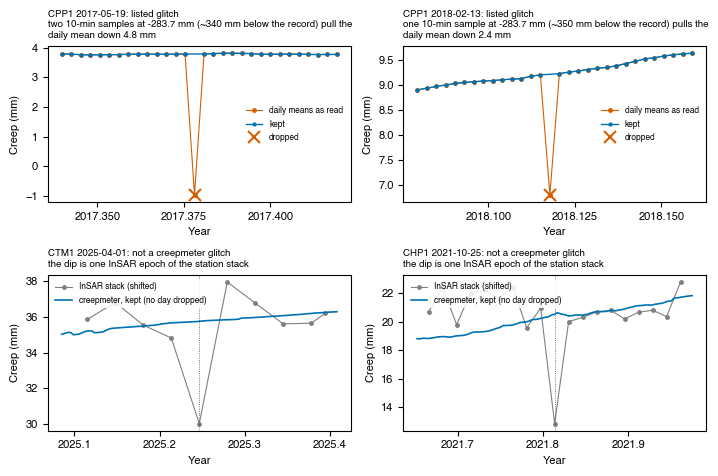

In [4]:
# [6b]
utils.mpl_paper_style(base=8)
qc_insar_dips = [("CTM1", "2025-04-01"), ("CHP1", "2021-10-25")]   # the InSAR epochs under the two dips (checked 2026-10-05)
qc_insar_half_days = 60                                          # days shown either side of an InSAR dip
glitches_in_window = []
for glitch_code, glitch_first, glitch_last, reason in creepmeter_glitches:
    glitch_mid = utils.date_to_decimal_year(pd.Timestamp(glitch_first).to_pydatetime())
    if t0 <= glitch_mid <= t1:
        glitches_in_window.append((glitch_code, glitch_first, glitch_last, reason))
n_panels = len(glitches_in_window) + len(qc_insar_dips)
fig, axes = plt.subplots(int(np.ceil(n_panels / 2)), 2, figsize=(7.2, 2.4 * np.ceil(n_panels / 2)), squeeze=False)
axes = axes.ravel()
for panel, (glitch_code, glitch_first, glitch_last, reason) in enumerate(glitches_in_window):
    ax = axes[panel]
    as_read = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], glitch_code), date_start=t0, date_end=t1)
    kept_dates, kept_slip = cm_data[glitch_code]
    offset = float(as_read.slip_mm.values[np.searchsorted(as_read.decimal_year.values, kept_dates[0])]) - kept_slip[0]   # both zeroed alike
    first_yr = utils.date_to_decimal_year(pd.Timestamp(glitch_first).to_pydatetime())
    last_yr = utils.date_to_decimal_year((pd.Timestamp(glitch_last) + pd.Timedelta(days=1)).to_pydatetime())
    shown = (as_read.decimal_year >= first_yr - qc_half_days / 365.25) & (as_read.decimal_year <= last_yr + qc_half_days / 365.25)
    dropped = shown & (as_read.decimal_year >= first_yr) & (as_read.decimal_year < last_yr)
    assert dropped.any(), f"{glitch_code} {glitch_first}: the glitch day is not in the record"
    kept_shown = (kept_dates >= first_yr - qc_half_days / 365.25) & (kept_dates <= last_yr + qc_half_days / 365.25)
    ax.plot(as_read.decimal_year[shown], as_read.slip_mm[shown] - offset, "o-", ms=2.5, lw=0.8, color="#D55E00", label="daily means as read")
    ax.plot(kept_dates[kept_shown], kept_slip[kept_shown], "o-", ms=2.0, lw=1.0, color="#0072B2", label="kept")
    ax.plot(as_read.decimal_year[dropped], as_read.slip_mm[dropped] - offset, "x", ms=8, mew=1.5, color="#D55E00", label="dropped")
    glitch_span = glitch_first if glitch_last == glitch_first else f"{glitch_first} to {glitch_last}"
    ax.set_title(f"{glitch_code} {glitch_span}: listed glitch\n" + textwrap.fill(reason, 70), loc="left", fontsize=7)
    ax.set_ylabel("Creep (mm)")
    ax.legend(fontsize=6, loc="center right")
for panel, (dip_code, dip_day) in enumerate(qc_insar_dips, start=len(glitches_in_window)):
    ax = axes[panel]
    dip_yr = utils.date_to_decimal_year(pd.Timestamp(dip_day).to_pydatetime())
    cm_dates, cm_slip = cm_data[dip_code]
    stack_dates, stack_mean, _, _, _ = insar_stacks[dip_code]
    near_cm = np.abs(cm_dates - dip_yr) <= qc_insar_half_days / 365.25
    near_insar = (np.abs(stack_dates - dip_yr) <= qc_insar_half_days / 365.25) & np.isfinite(stack_mean)
    assert np.any(np.abs(stack_dates[near_insar] - dip_yr) < 0.5 / 365.25), f"{dip_code}: no InSAR epoch on {dip_day}"
    insar_shift = np.median(np.interp(stack_dates[near_insar], cm_dates, cm_slip) - stack_mean[near_insar])   # display alignment only
    ax.plot(stack_dates[near_insar], stack_mean[near_insar] + insar_shift, "o-", ms=2.5, lw=0.8, color="0.5", label="InSAR stack (shifted)")
    ax.plot(cm_dates[near_cm], cm_slip[near_cm], "-", lw=1.2, color="#0072B2", label="creepmeter, kept (no day dropped)")
    ax.axvline(dip_yr, color="0.3", lw=0.6, ls=":")
    ax.set_title(f"{dip_code} {dip_day}: not a creepmeter glitch\nthe dip is one InSAR epoch of the station stack", loc="left", fontsize=7)
    ax.set_ylabel("Creep (mm)")
    ax.legend(fontsize=6, loc="upper left")
for ax in axes[n_panels:]:
    ax.set_visible(False)
for ax in axes[:n_panels]:
    ax.set_xlabel("Year")
    ax.ticklabel_format(axis="x", useOffset=False)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
fig.tight_layout()
fig_qc = os.path.join(fig_dir, "qc05_creepmeter_glitches.png")
fig.savefig(fig_qc, dpi=300)
print("Saved figure to:", fig_qc)
plt.show()

## [7] RUN: rates with bootstrap confidence intervals

Per station: the creepmeter rate, the crossing rate and the velocity-field
step, each with a moving-block bootstrap 95% CI (residuals resampled in
contiguous blocks, re-added to the fitted trend, refitted). Then the
cumulative misfit, and the detrended comparison: the correlation of the two
detrended series (does the InSAR see the same transients?) and the detrended
RMSE (the noise floor of the stack). The one step measure across an event
window is defined here: `event_step` (a collar each side of the window, one
straight line for the inter-event trend plus an offset between the collars;
the offset is the step). It gives the ladder's ratio ([20]) and the
creepmeter glitch check ([14b]).

In [5]:
# [8]
rng = np.random.default_rng(seed)


def slope(dates, values):
    """OLS slope in closed form, so the bootstrap refit is fast."""
    dates_centred = dates - dates.mean()
    return float(dates_centred @ (values - values.mean()) / (dates_centred @ dates_centred))


def block_indices(n_samples, block_len):
    """One moving-block resample: random contiguous blocks of block_len indices, joined and cut to n_samples."""
    n_blocks = int(np.ceil(n_samples / block_len))
    starts = rng.integers(0, n_samples - block_len + 1, size=n_blocks)
    blocks = []
    for start in starts:
        blocks.append(np.arange(start, start + block_len))
    return np.concatenate(blocks)[:n_samples]


def block_bootstrap_slope(dates, values, block_len):
    """Rate (slope of a straight line) with a moving-block bootstrap 95% CI: the residuals about the line
    are resampled in blocks of block_len samples, re-added to the line and refitted nboot times.
    Returns (rate, ci_lo, ci_hi)."""
    dates = np.asarray(dates, float)
    values = np.asarray(values, float)
    n_samples = len(dates)
    line = np.polyfit(dates, values, 1)
    trend = np.polyval(line, dates)
    residual = values - trend
    block_len = int(max(2, min(block_len, n_samples)))
    draws = np.empty(nboot)
    for draw in range(nboot):
        draws[draw] = slope(dates, trend + residual[block_indices(n_samples, block_len)])
    return line[0], np.percentile(draws, 2.5), np.percentile(draws, 97.5)


def step_fit(dist_m, velocity):
    """velocity = intercept + slope * dist + step * [dist > 0]: one straight line across the fault with a
    step at the trace. The step is the fault-crossing creep rate. Returns (intercept, slope, step)."""
    design_matrix = np.column_stack([np.ones_like(dist_m), dist_m, (dist_m > 0).astype(float)])
    intercept, gradient, step = np.linalg.lstsq(design_matrix, velocity, rcond=None)[0]
    return intercept, gradient, step


def block_bootstrap_step(dist_m, velocity):
    """Velocity step at the trace with a moving-block bootstrap 95% CI: residuals resampled in blocks of
    ~block_m along the profile. Returns (step, ci_lo, ci_hi)."""
    order = np.argsort(dist_m)
    dist_m = dist_m[order]
    velocity = velocity[order]
    intercept, gradient, step_best = step_fit(dist_m, velocity)
    prediction = intercept + gradient * dist_m + step_best * (dist_m > 0)
    residual = velocity - prediction
    n_samples = len(dist_m)
    block_len = int(max(3, round(n_samples * block_m / (dist_m.max() - dist_m.min()))))
    draws = np.empty(nboot)
    for draw in range(nboot):
        _, _, draws[draw] = step_fit(dist_m, prediction + residual[block_indices(n_samples, block_len)])
    return step_best, np.percentile(draws, 2.5), np.percentile(draws, 97.5)


def effective_sample_size(values):
    """Effective sample size under lag-1 autocorrelation r1: n (1 - r1) / (1 + r1). Returns (n_eff, r1)."""
    values = values[np.isfinite(values)]
    anomaly = values - values.mean()
    r1 = float(anomaly[1:] @ anomaly[:-1] / (anomaly @ anomaly))
    return len(values) * (1 - r1) / (1 + r1), r1


def ci95_to_sigma(ci_lo, ci_hi):
    """1-sigma from a 95% interval, assuming it is Gaussian: (hi - lo) / (2 x 1.96)."""
    return (ci_hi - ci_lo) / 3.92


def event_step(dates, cumulative, window_start, window_end):
    """Slip across one event window against the local inter-event trend, the one step method of this
    notebook: in the collars (collar_yr each side, never inside the window) ONE straight line (the trend,
    a common slope) plus an offset that applies after the window are fitted together; the offset is the
    step. (A single line through both collars, the method before 2026-10-05, takes up most of a short step
    in its slope: COZ1's 2022 surge, 4.86 mm in the catalogue, is 4.4 mm by this fit on the daily record
    and was 0.9 mm by that one.) The window edges are the acquisitions either side of the step (04's
    onset_lo and onset_hi), so the edge epochs belong to the collars: window_start is the last pre-event
    sample and window_end the first post-event one. Returns NaN (the event is not scored) when a collar has
    fewer than min_collar_epochs epochs or the two together fewer than min_fit_epochs finite epochs."""
    pre = (dates >= window_start - collar_yr) & (dates <= window_start)
    post = (dates >= window_end) & (dates <= window_end + collar_yr)
    if pre.sum() < min_collar_epochs or post.sum() < min_collar_epochs:
        return np.nan
    fit = np.isfinite(cumulative) & (pre | post)
    if fit.sum() < min_fit_epochs:
        return np.nan
    design_matrix = np.column_stack([np.ones(fit.sum()), dates[fit] - dates[fit].mean(), post[fit].astype(float)])
    return float(np.linalg.lstsq(design_matrix, cumulative[fit], rcond=None)[0][2])


rows = []
for code, lat, lon, name in creepmeters:
    cm_dates, cm_slip = cm_data[code]
    cm_step_yr = np.median(np.diff(cm_dates))
    cm_rate, cm_lo, cm_hi = block_bootstrap_slope(cm_dates, cm_slip, round(block_years / cm_step_yr))
    stack_dates, stack_mean, stack_std, n_rows, _ = insar_stacks[code]
    finite = np.isfinite(stack_mean)
    insar_dates = stack_dates[finite]
    insar_slip = stack_mean[finite]
    cr_rate, cr_lo, cr_hi = block_bootstrap_slope(insar_dates, insar_slip, round(block_years / np.median(np.diff(insar_dates))))
    transect = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    st_rate, st_lo, st_hi = block_bootstrap_step(transect["dist_m"].values.astype(float), transect["fp_vel"].values.astype(float))
    cm_on_insar_dates = np.interp(insar_dates, cm_dates, cm_slip)            # creepmeter ON the SAR epochs
    misfit = insar_slip - cm_on_insar_dates
    insar_detrended = utils.detrend(insar_dates, insar_slip)
    cm_detrended = utils.detrend(insar_dates, cm_on_insar_dates)
    both_finite = np.isfinite(insar_detrended) & np.isfinite(cm_detrended)
    n_effective, lag1_r = effective_sample_size(insar_detrended[both_finite])
    det_r = float(np.corrcoef(insar_detrended[both_finite], cm_detrended[both_finite])[0, 1])
    det_rmse = float(np.sqrt(np.mean((insar_detrended[both_finite] - cm_detrended[both_finite]) ** 2)))
    rows.append(dict(code=code, name=name, nstack=n_rows, nepoch=int(finite.sum()),
                     cm_rate=cm_rate, cm_lo=cm_lo, cm_hi=cm_hi, cr_rate=cr_rate, cr_lo=cr_lo, cr_hi=cr_hi,
                     st_rate=st_rate, st_lo=st_lo, st_hi=st_hi,
                     d_cross=cr_rate - cm_rate, d_step=st_rate - cm_rate, distributed=st_rate - cr_rate,
                     sig_cross=np.hypot(ci95_to_sigma(cr_lo, cr_hi), ci95_to_sigma(cm_lo, cm_hi)),
                     sig_step=np.hypot(ci95_to_sigma(st_lo, st_hi), ci95_to_sigma(cm_lo, cm_hi)),
                     cum_rmse=np.sqrt(np.mean(misfit ** 2)), cum_mad=1.4826 * np.median(np.abs(misfit - np.median(misfit))),
                     det_std_ins=np.nanstd(insar_detrended), det_std_cm=np.nanstd(cm_detrended),
                     det_rmse=det_rmse, det_r=det_r, det_r1=lag1_r, det_neff=n_effective))
    print(f"  {code}: creepmeter {cm_rate:5.2f} [{cm_lo:.2f}, {cm_hi:.2f}]  crossing {cr_rate:5.2f} [{cr_lo:.2f}, {cr_hi:.2f}]  "
          f"step {st_rate:5.2f} [{st_lo:.2f}, {st_hi:.2f}]  det r {det_r:.2f}  det RMSE {det_rmse:.2f} mm")
stations = pd.DataFrame(rows).set_index("code")
stations.to_csv(os.path.join(out_dir, "station_agreement.csv"))

  CPP1: creepmeter  5.05 [4.95, 5.14]  crossing  5.04 [4.78, 5.32]  step  3.65 [2.48, 4.76]  det r 0.27  det RMSE 1.79 mm


  CTM1: creepmeter  4.11 [4.02, 4.21]  crossing  4.19 [3.91, 4.48]  step  3.77 [3.29, 4.20]  det r 0.37  det RMSE 1.88 mm


  COZ1: creepmeter  4.43 [4.12, 4.75]  crossing  3.06 [2.82, 3.27]  step  3.09 [2.58, 3.61]  det r 0.58  det RMSE 1.66 mm


  CHP1: creepmeter  3.81 [3.75, 3.86]  crossing  4.20 [4.08, 4.32]  step  4.95 [4.31, 5.59]  det r -0.22  det RMSE 1.63 mm


  CFW1: creepmeter  6.99 [6.77, 7.21]  crossing  6.57 [6.44, 6.68]  step  6.58 [6.14, 7.03]  det r 0.32  det RMSE 1.51 mm


## [9] Ensemble agreement and the noise floor

Agreement is reported three ways because no single number suffices: rate
residual statistics (bias, RMS, reduced chi-square against the combined
CI), the same excluding COZ1, and the detrended RMSE. Two noise-floor
definitions are printed side by side; the text quotes the mean detrended
RMSE (~1.7 mm for a stack of up to 5 crossings).

In [6]:
# [10]
def agreement(table, key):
    """Agreement of one InSAR measure with the creepmeters over the stations in `table`, from the differences
    delta = InSAR - creepmeter (column d_<key>) and their combined 1-sigma (column sig_<key>):
    bias = mean(delta); RMS = sqrt(mean(delta^2)); weighted RMS with weights 1/sigma^2;
    reduced chi-square = mean((delta / sigma)^2); Bland-Altman limits = bias +/- 1.96 x sd(delta)."""
    delta = table[f"d_{key}"].values
    sigma = table[f"sig_{key}"].values
    weight = 1.0 / sigma ** 2
    bias = np.mean(delta)
    spread = np.std(delta, ddof=1)
    return dict(bias=bias, median_bias=np.median(delta), wrms=np.sqrt(np.sum(weight * delta ** 2) / np.sum(weight)),
                rms=np.sqrt(np.mean(delta ** 2)), chi2v=np.mean((delta / sigma) ** 2),
                ba_lo=bias - 1.96 * spread, ba_hi=bias + 1.96 * spread, maxabs=np.max(np.abs(delta)))


agreement_stats = {"cross": agreement(stations, "cross"), "step": agreement(stations, "step"),
                   "cross_excl_coz1": agreement(stations.drop("COZ1"), "cross")}
steady = stations[stations.det_std_cm < 1.0]                # stations whose creepmeter transient is sub-mm
floor_steady_std = float(steady.det_std_ins.median())       # there the detrended InSAR is pure epoch noise
floor_rmse = float(stations.det_rmse.mean())

stats_lines = ["=" * 78, "CREEPMETER vs INSAR: CREEP-RATE AGREEMENT", "=" * 78,
               f"InSAR window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr); creep bin {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, "
               f"along-strike +/-{x_width * 1000:.0f} m, coherence {coh_timeseries}",
               f"velocity-field step: +/-{max_dist_m:.0f} m transects, swath +/-{swath_m:.0f} m; InSAR stack <= {stack_max} rows "
               f"within +/-{stack_km * 1000:.0f} m of latitude",
               f"bootstrap: {nboot} moving-block resamples (block ~{block_years:g} yr / {block_m:.0f} m), seed {seed}", "",
               "PER-STATION RATES (mm/yr) [95% CI]",
               f"{'code':5} {'creepmeter':>22} {'crossing':>22} {'step':>22}"]
for code, station in stations.iterrows():
    stats_lines.append(f"{code:5} {station.cm_rate:6.2f} [{station.cm_lo:5.2f},{station.cm_hi:5.2f}]   "
                       f"{station.cr_rate:6.2f} [{station.cr_lo:5.2f},{station.cr_hi:5.2f}]   "
                       f"{station.st_rate:6.2f} [{station.st_lo:5.2f},{station.st_hi:5.2f}]")
stats_lines += ["", "DIFFERENCES vs CREEPMETER (mm/yr)", f"{'code':5} {'crossing-cm':>12} {'step-cm':>10} {'step-crossing':>14}"]
for code, station in stations.iterrows():
    stats_lines.append(f"{code:5} {station.d_cross:12.2f} {station.d_step:10.2f} {station.distributed:14.2f}")
stats_lines += ["", "TIME-SERIES AGREEMENT (creepmeter aligned to the InSAR epochs)",
                f"{'code':5} {'cum RMSE':>9} {'det.std ins/cm':>16} {'det.r':>7} {'det RMSE':>9} {'N_eff':>7} {'N_ep':>5}"]
for code, station in stations.iterrows():
    stats_lines.append(f"{code:5} {station.cum_rmse:9.2f} {station.det_std_ins:7.2f}/{station.det_std_cm:<7.2f} {station.det_r:7.2f} "
                       f"{station.det_rmse:9.2f} {station.det_neff:7.0f} {station.nepoch:5d}")
stats_lines += ["", "ENSEMBLE AGREEMENT"]
for key, label in (("cross", "crossing vs creepmeter, all 5"), ("cross_excl_coz1", "crossing vs creepmeter, excl COZ1"),
                   ("step", "velocity step vs creepmeter, all 5")):
    stats = agreement_stats[key]
    stats_lines.append(f"{label}: bias {stats['bias']:+.2f} (median {stats['median_bias']:+.2f}), RMS {stats['rms']:.2f}, "
                       f"weighted RMS {stats['wrms']:.2f}, max |diff| {stats['maxabs']:.2f} mm/yr, reduced chi2 {stats['chi2v']:.2f}, "
                       f"Bland-Altman [{stats['ba_lo']:+.2f}, {stats['ba_hi']:+.2f}]")
stats_lines += ["", "NOISE FLOOR",
                f"median detrended InSAR std at steady stations (creepmeter transient < 1 mm): {floor_steady_std:.2f} mm",
                f"mean detrended RMSE, InSAR minus creepmeter, all 5: {floor_rmse:.2f} mm "
                f"(range {stations.det_rmse.min():.2f} to {stations.det_rmse.max():.2f})"]
print("\n".join(stats_lines))

CREEPMETER vs INSAR: CREEP-RATE AGREEMENT
InSAR window 2016.672 to 2026.216 (9.54 yr); creep bin 30-150 m, along-strike +/-200 m, coherence 0.7
velocity-field step: +/-1000 m transects, swath +/-200 m; InSAR stack <= 5 rows within +/-200 m of latitude
bootstrap: 2000 moving-block resamples (block ~1 yr / 100 m), seed 0

PER-STATION RATES (mm/yr) [95% CI]
code              creepmeter               crossing                   step
CPP1    5.05 [ 4.95, 5.14]     5.04 [ 4.78, 5.32]     3.65 [ 2.48, 4.76]
CTM1    4.11 [ 4.02, 4.21]     4.19 [ 3.91, 4.48]     3.77 [ 3.29, 4.20]
COZ1    4.43 [ 4.12, 4.75]     3.06 [ 2.82, 3.27]     3.09 [ 2.58, 3.61]
CHP1    3.81 [ 3.75, 3.86]     4.20 [ 4.08, 4.32]     4.95 [ 4.31, 5.59]
CFW1    6.99 [ 6.77, 7.21]     6.57 [ 6.44, 6.68]     6.58 [ 6.14, 7.03]

DIFFERENCES vs CREEPMETER (mm/yr)
code   crossing-cm    step-cm  step-crossing
CPP1         -0.01      -1.40          -1.39
CTM1          0.08      -0.35          -0.42
COZ1         -1.38      -1.34    

## [11] CFW1: the slip across each Tule Pond InSAR onset window

CFW1 sits at the south end of the Tule Pond section. For each of the five
InSAR onset windows of notebook 04 (from the last acquisition before the
event to the first one after it), the slip the creepmeter recorded across the
window is measured from the raw 10-minute record: the median of the first 12
h after the window opens subtracted from the median of the last 12 h before
it closes (if an edge falls in a data gap, the nearest 12 h of data within 5
d on that side are used, and the span actually measured is printed). The
expected slip is CFW1's own long-term rate times that span; the data column
is the fraction of hours inside the window with any sample.

In [7]:
# [12]
events_all = pd.read_csv(events_file)
events_coz1 = events_all.query("segment == 'COZ1'")
events_tulepond = events_all.query("segment == 'TULEPOND'")
assert len(events_tulepond) == 5, f"expected the five Tule Pond events, got {len(events_tulepond)}"
assert len(events_coz1) == 2, f"expected the two Oakland (COZ1) events of notebook 04, got {len(events_coz1)}"

cfw_raw = utils.read_creepmeter_10min_raw(utils.creepmeter_file(common_paths["creepmeter_dir"], "CFW1"), date_start=t0, date_end=t1)
cfw_dates = cfw_raw.decimal_year.values
cfw_slip = cfw_raw.slip_mm.values
one_day_yr = 1 / 365.25
cfw_rate = stations.loc["CFW1", "cm_rate"]           # the instrument's own long-term rate over the InSAR window, mm/yr


def cfw_level(t_edge, side):
    """Median CFW1 slip in the cfw_edge_hours after (side=+1) or before (side=-1) t_edge. If that span has
    fewer than min_edge_samples samples (the edge is in a gap), the nearest cfw_edge_hours of data on that
    side within edge_search_days are used instead. Returns (level mm, median time of the samples used)."""
    edge_span_yr = cfw_edge_hours / 24 * one_day_yr
    if side > 0:
        in_span = (cfw_dates >= t_edge) & (cfw_dates < t_edge + edge_span_yr)
    else:
        in_span = (cfw_dates > t_edge - edge_span_yr) & (cfw_dates <= t_edge)
    if in_span.sum() < min_edge_samples:
        if side > 0:
            nearby = (cfw_dates >= t_edge) & (cfw_dates < t_edge + edge_search_days * one_day_yr)
        else:
            nearby = (cfw_dates > t_edge - edge_search_days * one_day_yr) & (cfw_dates <= t_edge)
        assert nearby.sum() >= min_edge_samples, f"no CFW1 data within {edge_search_days} d of {t_edge:.4f}"
        if side > 0:
            first_sample = cfw_dates[nearby][0]
            in_span = (cfw_dates >= first_sample) & (cfw_dates < first_sample + edge_span_yr)
        else:
            last_sample = cfw_dates[nearby][-1]
            in_span = (cfw_dates > last_sample - edge_span_yr) & (cfw_dates <= last_sample)
    return float(np.median(cfw_slip[in_span])), float(np.median(cfw_dates[in_span]))


cfw_rows = []
for _, event in events_tulepond.iterrows():
    window_start = event.onset_lo
    window_end = event.onset_hi
    level_start, time_start = cfw_level(window_start, +1)
    level_end, time_end = cfw_level(window_end, -1)
    in_window = (cfw_dates >= window_start) & (cfw_dates <= window_end)
    hours_with_data = len(np.unique(np.floor(cfw_dates[in_window] * 365.25 * 24)))
    window_hours = (window_end - window_start) * 365.25 * 24
    cover_pct = min(100.0, 100 * hours_with_data / window_hours)
    cfw_rows.append(dict(onset_lo=event.onset_lo, onset_hi=event.onset_hi, win_days=(window_end - window_start) * 365.25, cover_pct=cover_pct,
                         slip_win_mm=level_end - level_start, span_win_d=(time_end - time_start) * 365.25,
                         expect_win_mm=cfw_rate * (time_end - time_start), insar_mm=event.amplitude_mm))
cfw_windows = pd.DataFrame(cfw_rows)

cfw_lines = [f"CFW1 CREEPMETER SLIP ACROSS EACH TULE POND InSAR ONSET WINDOW (raw record; window edges = medians of "
             f"{cfw_edge_hours} h of data, nearest data if the edge is in a gap; expected = CFW1 rate {cfw_rate:.1f} mm/yr x span)",
             f"{'window':>17} {'win (d)':>7} {'data (%)':>8} {'slip in window (mm)':>19} {'span (d)':>8} {'expected (mm)':>13} {'InSAR step (mm)':>15}"]
for _, window in cfw_windows.iterrows():
    cfw_lines.append(f"{window.onset_lo:8.3f}-{window.onset_hi:8.3f} {window.win_days:7.0f} {window.cover_pct:8.0f} {window.slip_win_mm:19.2f} "
                     f"{window.span_win_d:8.1f} {window.expect_win_mm:13.2f} {window.insar_mm:15.1f}")
print("\n".join(cfw_lines))
stats_lines += [""] + cfw_lines                                   # into the stats file with the rest

CFW1 CREEPMETER SLIP ACROSS EACH TULE POND InSAR ONSET WINDOW (raw record; window edges = medians of 12 h of data, nearest data if the edge is in a gap; expected = CFW1 rate 7.0 mm/yr x span)
           window win (d) data (%) slip in window (mm) span (d) expected (mm) InSAR step (mm)
2017.099-2017.131      12      100                0.61     11.5          0.22             9.2
2019.186-2019.203       6      100                0.02      5.5          0.11             9.2
2021.107-2021.123       6      100                0.01      5.5          0.11             8.4
2023.080-2023.112      12      100                1.17     11.5          0.22             8.8
2024.984-2025.016      12      100                0.14     11.5          0.22             6.7


## [13] The InSAR onset windows against the published creepmeter catalogue

Gittins et al. (2026) list every aseismic slip event the USGS creepmeters
recorded up to December 2023 (digital catalogue v1.0.0). For each InSAR onset
window of notebook 04, Tule Pond against CFW1 and Oakland against COZ1, this
cell lists the catalogued events at that creepmeter that start inside the
window or overlap it (start on or before the window end and end on or after
the window start): start, end, displacement, duration and event type. The
InSAR dates carry the acquisition day but not the time of day, so a window
runs from the start of the pre-event acquisition day to the end of the
post-event acquisition day. A window that ends after the catalogue's last
event (the 2024-25 Tule Pond event) is marked "not covered" and is not
counted. Written to `gittins_comparison.csv`.

In [8]:
# [14]
gittins = pd.read_csv(common_paths["gittins_catalogue"], parse_dates=["Start Time", "End Time"])
catalogue_end = gittins["End Time"].max()                     # the end of the last catalogued event, any creepmeter
print(f"Gittins et al. (2026) catalogue: {len(gittins)} events, the last one ends {catalogue_end}")


def acquisition_day(decimal_year):
    """The calendar day of an acquisition from its decimal year (03 and 04 write the acquisition date at
    midnight, to 4 decimals, so the nearest midnight is the day)."""
    return (pd.Timestamp(utils.decimal_year_to_date(decimal_year)) + pd.Timedelta(hours=12)).normalize()


gittins_rows = []
gittins_counts = {}                       # creepmeter -> (windows covered by the catalogue, covered windows with a catalogued event)
gittins_lines = ["INSAR ONSET WINDOWS AGAINST THE GITTINS ET AL. (2026) CREEPMETER CATALOGUE "
                 "(events starting inside or overlapping the window)"]
for creepmeter_code, events_here in (("CFW1", events_tulepond), ("COZ1", events_coz1)):
    at_creepmeter = gittins[gittins["Creepmeter abbreviation"] == creepmeter_code]
    assert len(at_creepmeter) > 0, f"no {creepmeter_code} events in the Gittins catalogue"
    n_covered = 0
    n_matched = 0
    for event in events_here.itertuples():
        window_start = acquisition_day(event.onset_lo)                          # start of the pre-event acquisition day
        window_end = acquisition_day(event.onset_hi) + pd.Timedelta(days=1)     # end of the post-event acquisition day (exclusive)
        window_text = f"{creepmeter_code} window {window_start.date()} to {(window_end - pd.Timedelta(days=1)).date()}"
        row_base = dict(creepmeter=creepmeter_code, insar_segment=event.segment, onset_lo=event.onset_lo, onset_hi=event.onset_hi,
                        window_first_day=window_start.date(), window_last_day=(window_end - pd.Timedelta(days=1)).date())
        if window_end > catalogue_end:
            gittins_rows.append(dict(row_base, coverage="not covered", relation="", event_id="", start="", end="",
                                     displacement_mm=np.nan, duration_hrs=np.nan, event_type=""))
            gittins_lines.append(f"  {window_text}: not covered (the catalogue ends {catalogue_end.date()})")
            continue
        n_covered += 1
        starts_inside = (at_creepmeter["Start Time"] >= window_start) & (at_creepmeter["Start Time"] < window_end)
        overlaps = (at_creepmeter["Start Time"] < window_end) & (at_creepmeter["End Time"] >= window_start)    # includes starts_inside
        if overlaps.sum() == 0:
            before = at_creepmeter[at_creepmeter["Start Time"] < window_start]["Start Time"].max()
            after = at_creepmeter[at_creepmeter["Start Time"] > window_end]["Start Time"].min()
            gittins_rows.append(dict(row_base, coverage="covered", relation="none", event_id="", start="", end="",
                                     displacement_mm=np.nan, duration_hrs=np.nan, event_type=""))
            gittins_lines.append(f"  {window_text}: no catalogued event (nearest starts {before.date()} before, {after.date()} after)")
            continue
        n_matched += 1
        for index, catalogued in at_creepmeter[overlaps].iterrows():
            if starts_inside[index]:
                relation = "starts inside"
            else:
                relation = "overlaps"
            gittins_rows.append(dict(row_base, coverage="covered", relation=relation, event_id=catalogued["Event_id"],
                                     start=catalogued["Start Time"], end=catalogued["End Time"],
                                     displacement_mm=round(float(catalogued["Displacement, mm"]), 3),
                                     duration_hrs=round(float(catalogued["Duration, hrs"]), 1), event_type=catalogued["Event type"]))
            gittins_lines.append(f"  {window_text}: {relation}: {catalogued['Start Time']} to {catalogued['End Time']}, "
                                 f"{catalogued['Displacement, mm']:.2f} mm, {catalogued['Duration, hrs']:.0f} h, {catalogued['Event type']}")
    gittins_counts[creepmeter_code] = (n_covered, n_matched)
    gittins_lines.append(f"  {creepmeter_code}: {n_matched} of {n_covered} covered windows hold a catalogued event "
                         f"({len(events_here) - n_covered} not covered)")
gittins_comparison = pd.DataFrame(gittins_rows)
gittins_comparison.to_csv(os.path.join(out_dir, "gittins_comparison.csv"), index=False)
print("\n".join(gittins_lines))
stats_lines += [""] + gittins_lines                               # into the stats file with the rest

Gittins et al. (2026) catalogue: 5695 events, the last one ends 2024-01-11 06:59:00
INSAR ONSET WINDOWS AGAINST THE GITTINS ET AL. (2026) CREEPMETER CATALOGUE (events starting inside or overlapping the window)
  CFW1 window 2017-02-06 to 2017-02-18: starts inside: 2017-02-10 04:00:00 to 2017-02-15 21:40:00, 0.57 mm, 138 h, Episodic Creep Event (ECE)
  CFW1 window 2019-03-10 to 2019-03-16: no catalogued event (nearest starts 2019-02-07 before, 2019-03-21 after)
  CFW1 window 2021-02-09 to 2021-02-15: no catalogued event (nearest starts 2021-01-28 before, 2021-02-18 after)
  CFW1 window 2023-01-30 to 2023-02-11: overlaps: 2023-01-24 23:21:59 to 2023-02-03 15:47:59, 1.37 mm, 232 h, Episodic Creep Event (ECE)
  CFW1 window 2023-01-30 to 2023-02-11: starts inside: 2023-02-06 02:46:59 to 2023-02-13 12:31:59, 0.96 mm, 178 h, Episodic Creep Event (ECE)
  CFW1 window 2024-12-26 to 2025-01-07: not covered (the catalogue ends 2024-01-11)
  CFW1: 2 of 4 covered windows hold a catalogued event (1 n

## [14b] The CFW1 catalogue around the Tule Pond windows, its background rate, and the glitch check

The catalogue is used for TIMING only (its amplitude score, InSAR step /
catalogued slip, was retired on 2026-10-05; the transient amplitude is
notebook 04's, [14c]) and is not drawn on Fig S validation: it goes into a
table in the text (Dani 2026-10-05). The table's source is
`cfw1_gittins_near_windows.csv`: every CFW1 catalogue event, of any type,
whose start-to-end overlaps a Tule Pond InSAR onset window widened by
`gittins_window_pad_days` (7 d) on each side, with the window (first and
last acquisition day, as in [14]), the event's start and end (UTC, as
listed in the catalogue), slip and type, its timing relative to the window
in words (e.g. "inside", "5 d after", "starts 6 d before, ends inside"; in
calendar days between dates, so the dates-only table reproduces them), and
the slip CFW1 recorded across the
window ([12]). A window that ends after CFW1's last catalogued event is
listed once, as not covered.

Our InSAR at CFW1, for the same table: the fault-parallel step of each Tule
Pond event AT CFW1 is the mean of notebook 04's per-crossing joint-model
steps (`event_fraction_by_crossing.csv`, `amp_<onset_lo>`, the fit behind
Fig 1C; read, not recomputed) over the crossings within
`cfw1_insar_half_km` (0.2 km) along the trace of CFW1 (along-trace km from
`utils.lat_to_km_map`; CFW1's km from its coordinates). Its 1-sigma is the
noise of the same estimator: the standard deviation of the same +/-0.2 km
mean for the two Oakland (COZ1) control events, which put no slip on the
Tule Pond section, over independent 0.4 km windows along the measured Tule
Pond creep extent (`section_lengths.csv`); one sigma for all five events.

The background against which those events stand: the CFW1 catalogue rate
from the first InSAR acquisition day (2016-09-03) to the end of CFW1's last
catalogued event (all event types: count, events per year, median slip).

QC: across every catalogued event inside the InSAR window at each of the
five creepmeters, the creepmeter step (`event_step`, [8]; the window runs
from the last InSAR acquisition on a day before the event starts to the
first one on a day after it ends) on the daily record with the listed
glitch days dropped must agree with the step on the record as read within
`step_check_mm` (dropping them leaves the creep steps alone).

In [9]:
# [14b]
first_day = acquisition_day(t0)
last_day = acquisition_day(t1)
pad = pd.Timedelta(days=gittins_window_pad_days)
one_day = pd.Timedelta(days=1)
cfw1_catalogue = gittins[gittins["Creepmeter abbreviation"] == "CFW1"].sort_values("Start Time")
cfw1_end = cfw1_catalogue["End Time"].max()                   # the end of CFW1's last catalogued event


def timing_text(start, end, first_day, last_day):
    """Where a catalogued event falls relative to an InSAR window, in words, counted in CALENDAR days between
    dates so a reader of the dates-only table can reproduce it (Dani 2026-10-05): days after = event start
    date - window last day; days before = window first day - event start date; 'inside' when the start date
    is within [first day, last day] and the end date is not after the last day; 'starts N d before, ends
    inside' and 'starts inside, ends N d after' for the partial overlaps (N from the start or end date)."""
    start_date = start.normalize()
    end_date = end.normalize()
    if start_date > last_day:
        return f"{(start_date - last_day).days} d after"
    if end_date < first_day:
        return f"ends {(first_day - end_date).days} d before"             # (none in the current table)
    if start_date >= first_day:
        if end_date <= last_day:
            return "inside"
        return f"starts inside, ends {(end_date - last_day).days} d after"
    if end_date <= last_day:
        return f"starts {(first_day - start_date).days} d before, ends inside"
    return f"spans the window (starts {(first_day - start_date).days} d before, ends {(end_date - last_day).days} d after)"


# our InSAR AT CFW1: 04's per-crossing joint-model steps within +/- cfw1_insar_half_km along the trace of CFW1
to_km = utils.lat_to_km_map(common_paths["fault_profiles"])
event_steps = pd.read_csv(event_steps_file)
crossing_km = to_km(event_steps.lat.values)
assert np.allclose(crossing_km, event_steps.km.values, atol=0.051), "04's km column disagrees with lat_to_km_map"
cfw1_lat, cfw1_lon = [(lat, lon) for code, lat, lon, name in creepmeters if code == "CFW1"][0]
cfw1_km = float(to_km(cfw1_lat)[0])
trace = pd.read_csv(common_paths["fault_profiles"])            # check: the trace vertex nearest CFW1 by distance (100 m vertices)
trace_east_m = (trace.ft_lon.values - cfw1_lon) * 111190.0 * np.cos(np.radians(cfw1_lat))
trace_north_m = (trace.ft_lat.values - cfw1_lat) * 111190.0
nearest_vertex_km = (len(trace) - 1 - int(np.argmin(np.hypot(trace_east_m, trace_north_m)))) * 0.1
assert abs(cfw1_km - nearest_vertex_km) < 0.15, f"CFW1 at {cfw1_km} km by latitude but {nearest_vertex_km} km by distance to the trace"
near_cfw1 = np.abs(crossing_km - cfw1_km) <= cfw1_insar_half_km + 1e-6


def step_column(onset_lo):
    """04's per-crossing step column of the event at this step epoch (named by onset_lo, 3 decimals)."""
    column = f"amp_{onset_lo:.3f}"
    assert column in event_steps.columns, f"no per-crossing step {column} in {event_steps_file}"
    return column


# the noise of a +/- cfw1_insar_half_km mean: the two COZ1 events over independent windows of the Tule Pond extent
tulepond_extent = pd.read_csv(lengths_file).set_index("name").loc["tulepond_creep_length"]
null_means = []
window_centres = np.arange(tulepond_extent.km_lo + cfw1_insar_half_km, tulepond_extent.km_hi - cfw1_insar_half_km + 1e-6, 2 * cfw1_insar_half_km)
for event in events_coz1.itertuples():
    steps = event_steps[step_column(event.onset_lo)].values
    for centre in window_centres:
        in_null_window = (np.abs(crossing_km - centre) <= cfw1_insar_half_km + 1e-6) & np.isfinite(steps)
        if in_null_window.sum() >= 3:
            null_means.append(float(np.mean(steps[in_null_window])))
assert len(null_means) >= 10, f"only {len(null_means)} COZ1 null windows for the noise of the CFW1 step"
cfw1_insar_sigma = float(np.std(null_means, ddof=1))
cfw1_insar_steps = {}                     # event year -> (mean step mm, n crossings)
cfw1_insar_lines = [f"OUR InSAR AT CFW1 ({cfw1_km:.1f} km): mean of 04's per-crossing joint-model steps within +/-{cfw1_insar_half_km:g} km along "
                    f"the trace; 1-sigma {cfw1_insar_sigma:.2f} mm = std of the same mean for the two COZ1 events over {len(null_means)} "
                    f"independent {2 * cfw1_insar_half_km:g} km windows of the Tule Pond extent ({tulepond_extent.km_lo:.1f} to "
                    f"{tulepond_extent.km_hi:.1f} km; mean {np.mean(null_means):+.2f} mm, robust sigma {utils.robust_sigma(np.array(null_means)):.2f} mm)"]
for event in events_tulepond.itertuples():
    steps = event_steps[step_column(event.onset_lo)].values[near_cfw1]
    steps = steps[np.isfinite(steps)]
    assert len(steps) >= 3, f"{int(event.onset_lo)}: only {len(steps)} crossings with a step near CFW1"
    cfw1_insar_steps[int(event.onset_lo)] = (float(np.mean(steps)), len(steps))
    cfw1_insar_lines.append(f"  {int(event.onset_lo)}: {np.mean(steps):+.2f} +/- {cfw1_insar_sigma:.2f} mm ({len(steps)} crossings, "
                            f"spread across them {np.std(steps, ddof=1):.2f} mm)")
print("\n".join(cfw1_insar_lines))
stats_lines += [""] + cfw1_insar_lines                            # into the stats file with the rest

near_rows = []
near_lines = [f"CFW1 CATALOGUE EVENTS (ALL TYPES) OVERLAPPING EACH TULE POND InSAR WINDOW WIDENED BY +/-{gittins_window_pad_days} d "
              f"(Gittins et al. 2026; CFW1's last event ends {cfw1_end})"]
for event in events_tulepond.itertuples():
    window_start = acquisition_day(event.onset_lo)                          # start of the pre-event acquisition day
    window_end = acquisition_day(event.onset_hi) + one_day                  # end of the post-event acquisition day (exclusive)
    window_slip = cfw_windows.loc[np.isclose(cfw_windows.onset_lo, event.onset_lo, rtol=0, atol=1e-6), "slip_win_mm"]
    assert len(window_slip) == 1, f"window {event.onset_lo}: no single CFW1 window slip in [12]"
    row_base = dict(event_year=int(event.onset_lo), window_first_day=window_start.date(), window_last_day=(window_end - one_day).date(),
                    cfw1_window_slip_mm=round(float(window_slip.iloc[0]), 2),
                    insar_step_mm=round(cfw1_insar_steps[int(event.onset_lo)][0], 2))
    window_text = f"  {int(event.onset_lo)} window {window_start.date()} to {(window_end - one_day).date()}"
    if window_end + pad > cfw1_end:
        near_rows.append(dict(row_base, event_id="", start_utc="", end_utc="", slip_mm=np.nan, event_type="",
                              timing=f"window after the end of the CFW1 catalogue ({cfw1_end.date()})"))
        near_lines.append(f"{window_text}: not covered (CFW1's catalogue ends {cfw1_end.date()})")
        continue
    near = cfw1_catalogue[(cfw1_catalogue["Start Time"] < window_end + pad) & (cfw1_catalogue["End Time"] >= window_start - pad)]
    if len(near) == 0:
        near_lines.append(f"{window_text}: no catalogued event within +/-{gittins_window_pad_days} d")
    for _, catalogued in near.iterrows():
        timing = timing_text(catalogued["Start Time"], catalogued["End Time"], window_start, window_end - one_day)
        near_rows.append(dict(row_base, event_id=catalogued["Event_id"], start_utc=catalogued["Start Time"], end_utc=catalogued["End Time"],
                              slip_mm=round(float(catalogued["Displacement, mm"]), 2), event_type=catalogued["Event type"], timing=timing))
        near_lines.append(f"{window_text}: {catalogued['Event_id']} {catalogued['Start Time']} to {catalogued['End Time']}, "
                          f"{catalogued['Displacement, mm']:.2f} mm, {catalogued['Event type']}: {timing}")
    near_lines.append(f"{window_text}: CFW1 slip across the window {row_base['cfw1_window_slip_mm']:.2f} mm ([12])")
cfw1_near = pd.DataFrame(near_rows)                               # written in [14b2], with the InSAR step at each Gittins event

# the CFW1 background rate: every catalogued event (all types) starting from the first InSAR acquisition day to CFW1's catalogue end
background = cfw1_catalogue[cfw1_catalogue["Start Time"] >= first_day]
assert len(background) > 0, f"no CFW1 catalogue event after {first_day.date()}"
background_span_yr = (cfw1_end - first_day) / pd.Timedelta(days=365.25)
cfw1_rate_per_yr = len(background) / background_span_yr
cfw1_median_slip_mm = float(background["Displacement, mm"].median())
type_counts = []
for event_type, typed in background.groupby("Event type"):
    type_counts.append(f"{len(typed)} {event_type}")
near_lines.append(f"  CFW1 background {first_day.date()} to {cfw1_end.date()} ({background_span_yr:.2f} yr): {len(background)} events "
                  f"({', '.join(type_counts)}), {cfw1_rate_per_yr:.1f} per yr, median slip {cfw1_median_slip_mm:.2f} mm")

# QC: the glitch days dropped leave every catalogued creep step inside the InSAR window alone
glitch_check_rows = []                     # |step with - without the glitch days| per catalogued event with both collars
n_glitch_candidates = 0
for code, lat, lon, name in creepmeters:
    at_creepmeter = gittins[gittins["Creepmeter abbreviation"] == code]
    in_window = (at_creepmeter["Start Time"].dt.normalize() > first_day) & (at_creepmeter["End Time"].dt.normalize() < last_day)
    stack_dates, stack_mean, _, _, _ = insar_stacks[code]
    insar_dates = stack_dates[np.isfinite(stack_mean)]
    insar_days = np.array([acquisition_day(insar_date) for insar_date in insar_dates])
    cm_dates, cm_slip = cm_data[code]
    as_read = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code), date_start=t0, date_end=t1)
    for _, catalogued in at_creepmeter[in_window].iterrows():
        n_glitch_candidates += 1
        before = insar_days < catalogued["Start Time"].normalize()
        after = insar_days > catalogued["End Time"].normalize()
        assert before.any() and after.any(), f"{catalogued['Event_id']}: no acquisition before or after the event"
        window_lo = float(insar_dates[before][-1])                # the last acquisition before the event
        window_hi = float(insar_dates[after][0])                  # the first acquisition after it
        cm_step = event_step(cm_dates, cm_slip, window_lo, window_hi)
        cm_step_as_read = event_step(as_read.decimal_year.values, as_read.slip_mm.values, window_lo, window_hi)
        if np.isfinite(cm_step):
            assert abs(cm_step - cm_step_as_read) < step_check_mm, (f"{catalogued['Event_id']}: dropping the glitch days moved the creepmeter step "
                                                                   f"from {cm_step_as_read:.3f} to {cm_step:.3f} mm")
            glitch_check_rows.append(abs(cm_step - cm_step_as_read))
assert len(glitch_check_rows) > 0, "the glitch check scored no catalogued event"
near_lines.append(f"  glitch check: {len(glitch_check_rows)} of the {n_glitch_candidates} catalogued events inside the InSAR window (five "
                  f"creepmeters) have both collars; the creepmeter step with vs without the glitch days dropped differs by at most "
                  f"{max(glitch_check_rows):.3f} mm (limit {step_check_mm} mm)")
print("\n".join(near_lines))
stats_lines += [""] + near_lines                                  # into the stats file with the rest

OUR InSAR AT CFW1 (62.6 km): mean of 04's per-crossing joint-model steps within +/-0.2 km along the trace; 1-sigma 0.99 mm = std of the same mean for the two COZ1 events over 30 independent 0.4 km windows of the Tule Pond extent (56.2 to 62.4 km; mean +0.18 mm, robust sigma 0.86 mm)
  2017: +0.12 +/- 0.99 mm (5 crossings, spread across them 0.81 mm)
  2019: +1.53 +/- 0.99 mm (5 crossings, spread across them 1.27 mm)
  2021: +0.56 +/- 0.99 mm (5 crossings, spread across them 0.41 mm)
  2023: +0.98 +/- 0.99 mm (5 crossings, spread across them 1.02 mm)
  2024: -1.19 +/- 0.99 mm (5 crossings, spread across them 0.99 mm)


CFW1 CATALOGUE EVENTS (ALL TYPES) OVERLAPPING EACH TULE POND InSAR WINDOW WIDENED BY +/-7 d (Gittins et al. 2026; CFW1's last event ends 2023-09-01 05:21:59)
  2017 window 2017-02-06 to 2017-02-18: 4021_CFW1 2017-02-10 04:00:00 to 2017-02-15 21:40:00, 0.57 mm, Episodic Creep Event (ECE): inside
  2017 window 2017-02-06 to 2017-02-18: CFW1 slip across the window 0.61 mm ([12])
  2019 window 2019-03-10 to 2019-03-16: 4414_CFW1 2019-03-21 04:39:59 to 2019-03-23 03:00:00, 0.62 mm, Episodic Creep Event (ECE): 5 d after
  2019 window 2019-03-10 to 2019-03-16: 4416_CFW1 2019-03-23 21:29:59 to 2019-03-27 03:20:00, 0.31 mm, Episodic Creep Event (ECE): 7 d after
  2019 window 2019-03-10 to 2019-03-16: CFW1 slip across the window 0.02 mm ([12])
  2021 window 2021-02-09 to 2021-02-15: 4951_CFW1 2021-02-18 05:17:59 to 2021-02-19 09:22:00, 0.54 mm, Episodic Creep Event (ECE): 3 d after
  2021 window 2021-02-09 to 2021-02-15: CFW1 slip across the window 0.01 mm ([12])
  2023 window 2023-01-30 to 2023

## [14b2] Can our InSAR see the catalogued CFW1 events next to the Tule Pond windows?

For each CFW1 catalogue event of `cfw1_gittins_near_windows.csv` whose start
falls in a DIFFERENT acquisition interval from the Tule Pond window, a step
is added to the paper's joint model (M5) and its amplitude read at CFW1. The
model is notebook 04's, REPLICATED here (04 is a notebook, not a module, so
it cannot be imported): constant + rate + annual sine and cosine + one
Heaviside step H(t > step epoch) per event, on the common-grid dates of
`fp_ts.csv`, fitted per crossing by least squares on the finite epochs. It
keeps all of 04's steps (the five Tule Pond and the two Oakland onsets,
`creep_events.csv`, step epoch `onset_lo`) and adds, for each such Gittins
event, a step at the last common-grid epoch on a day before the event's start
date, so the step sits in the interval holding the start. That the
replication is exact is asserted: with 04's steps alone it reproduces 04's
per-crossing amplitudes at these crossings to 1e-6 mm. The crossings are
those of [14b] (within `cfw1_insar_half_km` along the trace of CFW1); the
step at CFW1 is their mean. A Gittins event whose start lies in the Tule Pond
step's own interval cannot be separated from it; the table carries the Tule
Pond step ([14b]) for it.

Uncertainty: the noise of a single-interval step of this same estimator at
CFW1, the standard deviation of the CFW1 mean step at `noise_n_trials` (40)
trial step epochs, each fitted with the same full model plus that one trial
step. The trials are drawn (seed `noise_seed`) from the acquisition intervals
at least `noise_clear_days` (60 d) from every 04 onset window, from every CFW1
catalogue event of at least `noise_gittins_min_mm` (0.3 mm, start to end), and
from both ends of the record. The catalogue ends in 2023, so intervals after
it are clear only of the 04 onsets (the printout gives how many of the trials
are inside the catalogue period, and the sigma from those alone).

Interpolation caveat: the common grid interpolates each track onto the union
of dates. For each added interval the printout says whether both tracks were
really acquired on its two bounding days (03's per-track dates).

In [10]:
# [14b2]
def joint_design(dates, step_epochs):
    """Notebook 04's design ([8] design(), replicated): constant, rate, annual sin and cos, then one
    Heaviside step H(t > step epoch) per event."""
    columns = [np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    for step_epoch in step_epochs:
        columns.append((dates > step_epoch).astype(float))
    return np.column_stack(columns)


def cfw1_steps(step_epochs):
    """The joint model fitted at each CFW1 crossing; returns the step amplitudes (n crossings x n steps)."""
    design_matrix = joint_design(grid_dates, step_epochs)
    amplitudes = []
    for values in cfw1_series:
        finite = np.isfinite(values)
        coef, *_ = np.linalg.lstsq(design_matrix[finite], values[finite], rcond=None)
        amplitudes.append(coef[4:])
    return np.array(amplitudes)


# the CFW1 crossings of [14b], on the common grid
grid_dates = fp_ts.columns.values.astype(float)
grid_days = pd.DatetimeIndex([acquisition_day(grid_date) for grid_date in grid_dates])
fp_ts_km = to_km(fp_ts.index.values)
cfw1_rows = np.abs(fp_ts_km - cfw1_km) <= cfw1_insar_half_km + 1e-6
assert np.allclose(np.sort(fp_ts.index.values[cfw1_rows]), np.sort(event_steps.lat.values[near_cfw1]), rtol=0, atol=1e-6), \
    "the fp_ts crossings near CFW1 are not 04's crossings of [14b]"
cfw1_series = fp_ts.values[cfw1_rows]
assert (np.isfinite(cfw1_series).sum(axis=1) >= 0.5 * len(grid_dates)).all(), "a CFW1 crossing has too few epochs for 04's fit"

# the replication check: 04's steps alone reproduce 04's per-crossing amplitudes here
base_steps = list(events_all.onset_lo.values)                      # 04's step epochs: Tule Pond and Oakland
base_amplitudes = cfw1_steps(base_steps)
order = np.argsort(fp_ts.index.values[cfw1_rows])
for k, event in enumerate(events_all.itertuples()):
    from_04 = event_steps.loc[near_cfw1].sort_values("lat")[step_column(event.onset_lo)].values
    assert np.allclose(base_amplitudes[order, k], from_04, atol=1e-6), f"the replicated joint model misses 04's step at {event.onset_lo}"

# one added step per Gittins event whose start is in a different interval from its Tule Pond window
added = []                                # (row index in cfw1_near, Event_id, step epoch)
same_interval = []
for row_index, near_row in cfw1_near.iterrows():
    if near_row.event_id == "":
        continue
    tulepond_lo = events_tulepond.onset_lo.values[[int(lo) == near_row.event_year for lo in events_tulepond.onset_lo]]
    assert len(tulepond_lo) == 1, f"{near_row.event_id}: no single Tule Pond event in {near_row.event_year}"
    before_start = np.flatnonzero(grid_days < pd.Timestamp(near_row.start_utc).normalize())
    step_epoch = float(grid_dates[before_start[-1]])                # the last common-grid epoch on a day before the start
    if np.isclose(step_epoch, tulepond_lo[0], rtol=0, atol=1e-6):        # rtol=0: decimal years, a relative 1e-5 is ~7 days
        same_interval.append((row_index, near_row.event_id))
    else:
        added.append((row_index, near_row.event_id, step_epoch))
added_epochs = [step_epoch for _, _, step_epoch in added]
assert len(set(added_epochs)) == len(added_epochs), "two Gittins events share an added interval: merge them"
full_steps = base_steps + added_epochs
full_amplitudes = cfw1_steps(full_steps)
gittins_step = {}                         # Event_id -> mean step at CFW1 (mm)
for k, (row_index, event_id, step_epoch) in enumerate(added):
    gittins_step[event_id] = float(np.mean(full_amplitudes[:, len(base_steps) + k]))

# the noise of a single-interval step: trial epochs in clear intervals, each with the full model
clear_yr = noise_clear_days / 365.25
busy_spans = [(event.onset_lo, event.onset_hi) for event in events_all.itertuples()]
cfw1_large = cfw1_catalogue[cfw1_catalogue["Displacement, mm"] >= noise_gittins_min_mm]
for _, catalogued in cfw1_large.iterrows():
    busy_spans.append((utils.date_to_decimal_year(catalogued["Start Time"].to_pydatetime()),
                       utils.date_to_decimal_year(catalogued["End Time"].to_pydatetime())))
clear_epochs = []
for k in range(len(grid_dates) - 1):
    interval_lo, interval_hi = grid_dates[k], grid_dates[k + 1]
    if interval_lo < grid_dates[0] + clear_yr or interval_hi > grid_dates[-1] - clear_yr:
        continue
    if all(interval_hi <= span_lo - clear_yr or interval_lo >= span_hi + clear_yr for span_lo, span_hi in busy_spans):
        clear_epochs.append(interval_lo)
assert len(clear_epochs) >= noise_n_trials, f"only {len(clear_epochs)} clear intervals for {noise_n_trials} trials"
trial_epochs = np.sort(np.random.default_rng(noise_seed).choice(clear_epochs, size=noise_n_trials, replace=False))
trial_means = []
for trial_epoch in trial_epochs:
    trial_means.append(float(np.mean(cfw1_steps(full_steps + [trial_epoch])[:, -1])))
trial_means = np.array(trial_means)
gittins_step_sigma = float(np.std(trial_means, ddof=1))
catalogue_end_yr = utils.date_to_decimal_year(cfw1_end.to_pydatetime())
in_catalogue = trial_epochs < catalogue_end_yr - clear_yr
sigma_in_catalogue = float(np.std(trial_means[in_catalogue], ddof=1)) if in_catalogue.sum() >= 3 else np.nan

# the interpolation caveat: were both tracks acquired on each bounding day?
track_days = {}
for track in ("ascending", "descending"):
    track_dates = pd.read_csv(os.path.join(paths_out["03_creep_timeseries"], f"creep_ts_LOS_{track}.csv"), index_col=0, nrows=0).columns
    track_days[track] = set(acquisition_day(float(track_date)) for track_date in track_dates)

gittins_lines = [f"OUR InSAR AT THE CFW1 CATALOGUE EVENTS (04's joint model replicated, + one step per Gittins event in its own interval; "
                 f"mean of the {cfw1_rows.sum()} crossings of [14b]); 1-sigma {gittins_step_sigma:.2f} mm = std of the CFW1 mean step at "
                 f"{noise_n_trials} trial epochs (seed {noise_seed}) from {len(clear_epochs)} intervals >= {noise_clear_days} d from every 04 "
                 f"onset and CFW1 event >= {noise_gittins_min_mm:g} mm (trial mean {trial_means.mean():+.2f} mm; {in_catalogue.sum()} trials "
                 f"inside the catalogue period, sigma {sigma_in_catalogue:.2f} mm from those alone)"]
insar_at_gittins = np.full(len(cfw1_near), np.nan)
for row_index, event_id, step_epoch in added:
    k = int(np.flatnonzero(np.isclose(grid_dates, step_epoch, rtol=0, atol=1e-6))[0])
    first_day_interval, last_day_interval = grid_days[k], grid_days[k + 1]
    both_tracks = all(day in track_days[track] for day in (first_day_interval, last_day_interval) for track in track_days)
    observed = ", ".join(f"{day.date()} " + "+".join(track[:4] for track in track_days if day in track_days[track])
                         for day in (first_day_interval, last_day_interval))
    insar_at_gittins[row_index] = gittins_step[event_id]
    gittins_lines.append(f"  {event_id} ({cfw1_near.loc[row_index, 'start_utc']}, {cfw1_near.loc[row_index, 'slip_mm']:.2f} mm): interval "
                         f"{first_day_interval.date()} to {last_day_interval.date()}: InSAR {gittins_step[event_id]:+.2f} +/- "
                         f"{gittins_step_sigma:.2f} mm ({abs(gittins_step[event_id]) / gittins_step_sigma:.1f} sigma, "
                         f"{'above' if abs(gittins_step[event_id]) > 2 * gittins_step_sigma else 'not above'} 2 sigma); "
                         f"both tracks real at both ends: {'Y' if both_tracks else 'N'} ({observed})")
for row_index, event_id in same_interval:
    insar_at_gittins[row_index] = cfw1_near.loc[row_index, "insar_step_mm"]
    gittins_lines.append(f"  {event_id}: starts in the Tule Pond step's own interval, not separable; the Tule Pond step "
                         f"{cfw1_near.loc[row_index, 'insar_step_mm']:+.2f} mm ([14b]) stands for it")
for k, event in enumerate(events_tulepond.itertuples()):
    column = base_steps.index(event.onset_lo)
    gittins_lines.append(f"  Tule Pond {int(event.onset_lo)} step at CFW1 with the added steps in the model: "
                         f"{np.mean(full_amplitudes[:, column]):+.2f} mm (without: {np.mean(base_amplitudes[:, column]):+.2f} mm)")
cfw1_near["insar_step_at_gittins_mm"] = np.round(insar_at_gittins, 2)
cfw1_near.to_csv(os.path.join(out_dir, "cfw1_gittins_near_windows.csv"), index=False)
print("\n".join(gittins_lines))
stats_lines += [""] + gittins_lines                               # into the stats file with the rest

OUR InSAR AT THE CFW1 CATALOGUE EVENTS (04's joint model replicated, + one step per Gittins event in its own interval; mean of the 5 crossings of [14b]); 1-sigma 1.22 mm = std of the CFW1 mean step at 40 trial epochs (seed 20261005) from 93 intervals >= 60 d from every 04 onset and CFW1 event >= 0.3 mm (trial mean -0.25 mm; 10 trials inside the catalogue period, sigma 0.46 mm from those alone)
  4414_CFW1 (2019-03-21 04:39:59, 0.62 mm): interval 2019-03-16 to 2019-03-22: InSAR +0.21 +/- 1.22 mm (0.2 sigma, not above 2 sigma); both tracks real at both ends: N (2019-03-16 asce+desc, 2019-03-22 asce)
  4416_CFW1 (2019-03-23 21:29:59, 0.31 mm): interval 2019-03-22 to 2019-03-28: InSAR +1.86 +/- 1.22 mm (1.5 sigma, not above 2 sigma); both tracks real at both ends: N (2019-03-22 asce, 2019-03-28 asce+desc)
  4951_CFW1 (2021-02-18 05:17:59, 0.54 mm): interval 2021-02-15 to 2021-02-21: InSAR +0.07 +/- 1.22 mm (0.1 sigma, not above 2 sigma); both tracks real at both ends: Y (2021-02-15 asce+de

## [14c] REPORT: the transient amplitude, notebook 04's joint model at COZ1

The amplitude statement of the paper (Dani 2026-10-05): how much of the
two large COZ1 creepmeter events the InSAR recovers, from notebook 04's
joint model (the InSAR amplitude `amplitude_mm` of each Oakland event against
the creepmeter's step `creepmeter_step_mm` over the same window, registry
`04_control_coz1_amp_*` and `04_control_coz1_creepmeter_*`). Read from 04's
`creep_events.csv` (not retyped) and checked against 04's registered values;
the recovery per event and its mean (~60%) are registered here.

In [11]:
# [14c]
latest_registry = REG.latest().set_index("key")
recovery_lines = ["TRANSIENT AMPLITUDE: NOTEBOOK 04 JOINT-MODEL COZ1 AMPLITUDE / CREEPMETER STEP (creep_events.csv)"]
recovery_pct = {}
for event in events_coz1.itertuples():
    label = f"{int(event.onset_lo)}"                                  # 04's key label: the year of the step epoch
    for column, key in (("amplitude_mm", f"04_control_coz1_amp_{label}_mm"), ("creepmeter_step_mm", f"04_control_coz1_creepmeter_{label}_mm")):
        assert key in latest_registry.index, f"{key} is not in the registry: run notebook 04"
        registered = latest_registry.loc[key]
        assert utils.render_value(getattr(event, column), int(registered["precision"])) == registered["rendered"], (
            f"{key}: creep_events.csv has {getattr(event, column)}, the registry {registered['rendered']}: 04's outputs and registry disagree")
    recovery_pct[label] = 100 * event.amplitude_mm / event.creepmeter_step_mm
    assert 0 < recovery_pct[label] < 150, f"COZ1 {label}: recovery {recovery_pct[label]:.0f}% is outside 0 to 150%"
    recovery_lines.append(f"  {label}: InSAR {event.amplitude_mm:.2f} mm / creepmeter {event.creepmeter_step_mm:.2f} mm = {recovery_pct[label]:.0f}%")
assert sorted(recovery_pct) == ["2019", "2022"], f"expected the 2019 and 2022 COZ1 events, got {sorted(recovery_pct)}"
recovery_mean_pct = float(np.mean(list(recovery_pct.values())))
assert 0 < recovery_mean_pct < 150, f"mean COZ1 recovery {recovery_mean_pct:.0f}% is outside 0 to 150%"
recovery_lines.append(f"  mean of the two: {recovery_mean_pct:.0f}%")
print("\n".join(recovery_lines))
stats_lines += [""] + recovery_lines                              # into the stats file with the rest

TRANSIENT AMPLITUDE: NOTEBOOK 04 JOINT-MODEL COZ1 AMPLITUDE / CREEPMETER STEP (creep_events.csv)
  2019: InSAR 2.29 mm / creepmeter 3.94 mm = 58%
  2022: InSAR 4.67 mm / creepmeter 7.31 mm = 64%
  mean of the two: 61%


## [15] Figure set-up: the map in the strike frame and its display reference

The map is the rotated fault map of Fig 1A, drawn by the same function
(`utils.fault_map_panel`): GMT's oblique Mercator over the same strike-frame
rectangle (u along the 144 deg strike from 3 km north of Point Pinole to just
south of CFW1, v +/- 10.9 km across the fault, + east), so the fault runs up
the page with north at the top, and everything is plotted in lon/lat. The
fault-parallel velocity is looked up once on a regular lon/lat grid (nearest
UTM pixel). For DISPLAY only, the mid-point of the two blocks' medians in the
CTM1-COZ1 patch is removed, so the fault sits at zero and the colours swing
equally blue (west) and red (east). (A plain patch mean is biased toward
whichever block has more valid pixels.) The SSE extent bracket is the
measured length of fault hosting the events from notebook 04
(`section_lengths.csv`), as in Fig 1A.

In [12]:
# [16]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text (the ladder figure below)

with h5py.File(map_file, "r") as map_h5:
    fp_map = map_h5["fp_velocity"][:].astype(float)
    attrs = {}
    for attr_name, attr_value in map_h5.attrs.items():
        if isinstance(attr_value, bytes):
            attrs[attr_name] = attr_value.decode()
        else:
            attrs[attr_name] = str(attr_value)
fp_map[fp_map == 0] = np.nan
x_fault = pd.read_csv(common_paths["fault_profiles"])
# the strike frame: u along the mean strike from Point Pinole (km, + south), v across the fault (km, + east)
frame = utils.strike_frame(int(attrs["EPSG"]), strike, x_fault["ft_lon"].values, x_fault["ft_lat"].values)
_, _, corners = utils.fault_map_corners(frame)                 # the rectangle of the shared fault map (as Fig 1A)

# the FP velocity on a regular lon/lat grid (nearest UTM pixel)
lon_axis, lat_axis, fp_lonlat = utils.utm_grid_to_lonlat(fp_map, float(attrs["X_FIRST"]), float(attrs["X_STEP"]),
                                                         float(attrs["Y_FIRST"]), float(attrs["Y_STEP"]), frame["to_utm"], corners)
lon_grid, lat_grid = np.meshgrid(lon_axis, lat_axis)
u_grid, v_grid = utils.to_uv(frame, lon_grid, lat_grid)                    # strike-frame coordinates of the grid nodes

# display reference: the mid-point of the two blocks' medians in the CTM1-COZ1 patch (as Fig 1A)
u_creepmeter, _ = utils.creepmeter_u_km(frame, x_fault["ft_lon"].values, x_fault["ft_lat"].values, creepmeters)
patch_lo, patch_hi = sorted([u_creepmeter["CTM1"], u_creepmeter["COZ1"]])
in_patch = (u_grid >= patch_lo) & (u_grid <= patch_hi)
fp_west = np.nanmedian(fp_lonlat[in_patch & (v_grid < 0) & (v_grid >= -ref_patch_km)])
fp_east = np.nanmedian(fp_lonlat[in_patch & (v_grid > 0) & (v_grid <= ref_patch_km)])
ref_mean = 0.5 * (fp_west + fp_east)
print(f"map display reference: west block {fp_west:+.2f}, east block {fp_east:+.2f} mm/yr; mid-point {ref_mean:+.2f} removed")
grid_ll = xr.DataArray(fp_lonlat - ref_mean, coords={"lat": lat_axis, "lon": lon_axis}, dims=("lat", "lon"))

# the SSE extent bracket: the MEASURED length of fault hosting the events from notebook 04 (km from Point Pinole), as Fig 1A
section = pd.read_csv(lengths_file).set_index("name").loc["tulepond_creep_length"]
print(f"SSE extent bracket: {section.km_lo:.1f} to {section.km_hi:.1f} km")

map display reference: west block +1.31, east block +5.79 mm/yr; mid-point +3.55 removed
SSE extent bracket: 56.2 to 62.4 km


## [17] Figure: the five creepmeters against the InSAR

Column 1 (A): the fault-parallel velocity map, the same panel as Fig 1A: fault
up the page at the mean strike (the trace stays curved, north at the top),
creepmeters as yellow triangles, the cities, the SSE extent bracket, the
distance from Point Pinole down the left edge. Columns 2 to 4, one row per creepmeter north
to south: (B-F) the cross-fault velocity profile with its step; (G-K)
cumulative creep, creepmeter (blue) against InSAR (grey, +/-1 std of the
stacked rows); (L-P) the same detrended. The InSAR onsets are orange
long-dashed lines at each step epoch (`onset_lo`; the orange of Fig 3A's
InSAR detection lines) in the rows they belong to (COZ1: the Oakland stack of
notebook 04; CFW1: the Tule Pond events), in both the cumulative and the
detrended panels, under the data; their key ('InSAR detection') is in N and P. The creepmeter
catalogue of Gittins et al. (2026) is not drawn (Dani 2026-10-05): it is a
table in the text ([14b]). The G-K legends (and the keys in N and P) sit in the
bottom-right corner with their bottom line on the baseline of the
'Velocity step' annotation of B-F. Colours are Okabe-Ito. Saved at 600 dpi.

The figure follows the Science supplement rules: 18.3 cm wide (single page
width), Helvetica 7 to 9 pt, bold panel letters with the description in
normal weight, the colour bar labelled. The map is drawn at true scale, so
its width follows its height.

map panel 3.69 x 11.90 cm at true scale


data panels 3.80 x 2.10 cm; figure 18.1 cm wide with 0.9 cm for the map's distance axis


/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/pygmt/src/legend.py:160: SyntaxWarning: Short-form parameter 'S' is not recommended. Use long-form parameter 'scale' instead.
  aliasdict.merge(kwargs)


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-03_final/figS_validation_cohmap0.7_ap30-150m_coh0.7_mp5_sw200m_profile1000m_stack5x200m.png


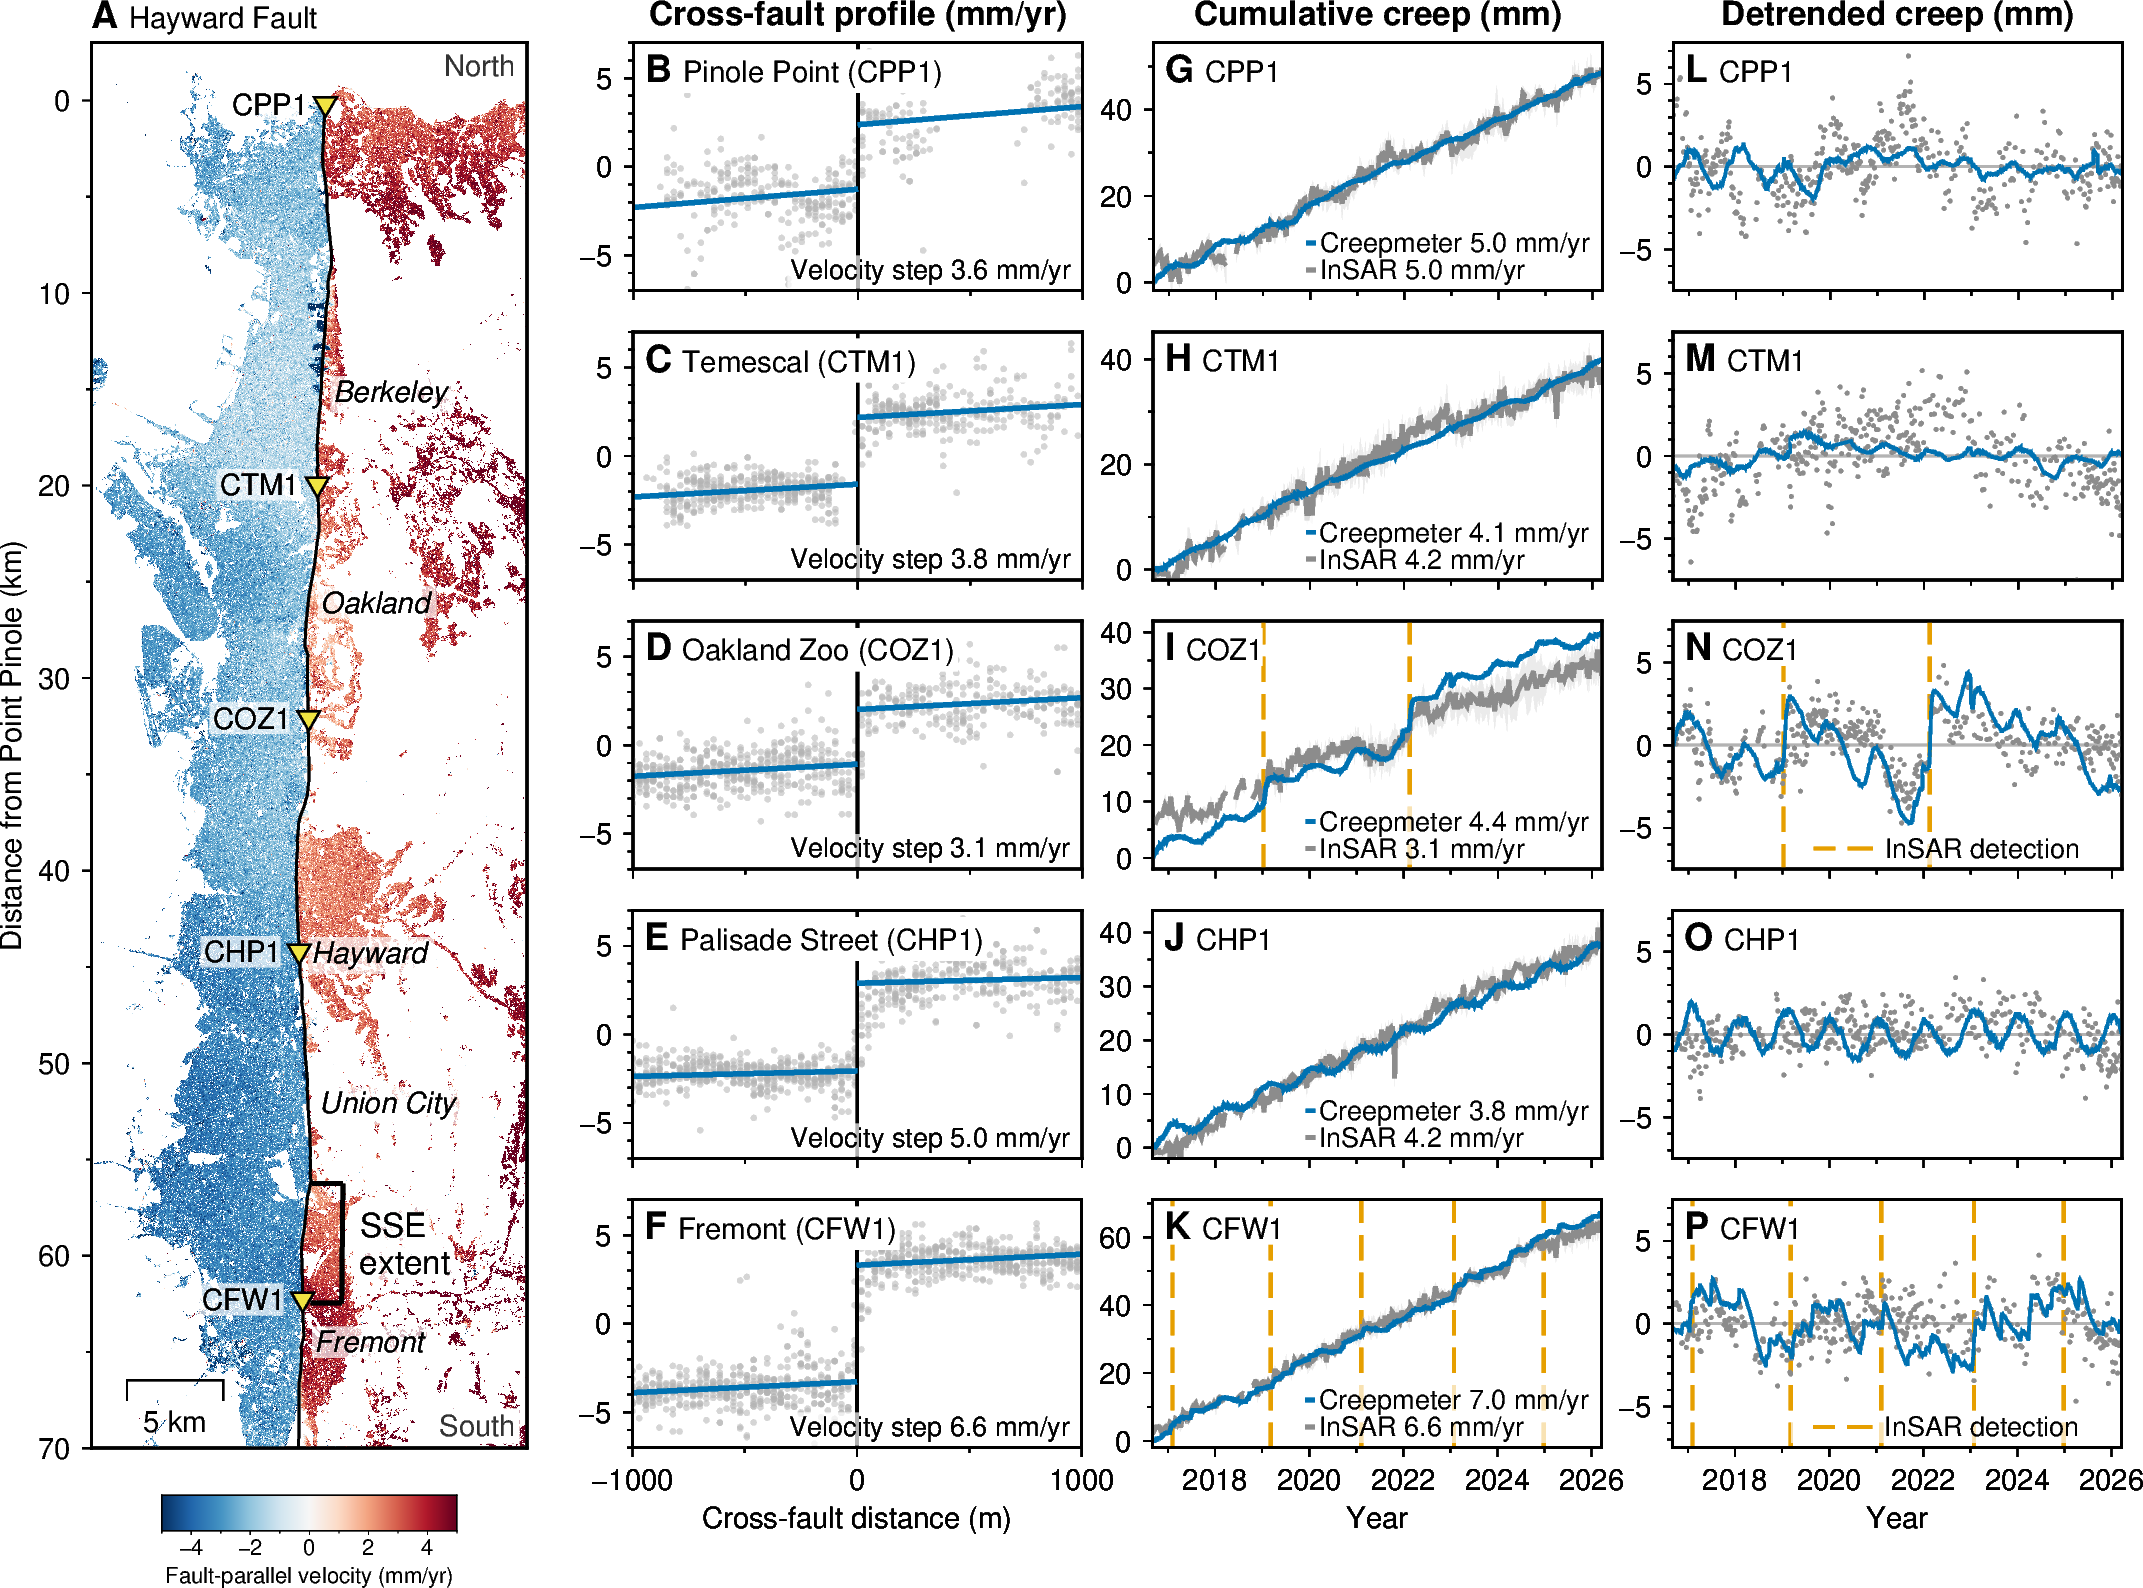

In [13]:
# [18]
def runs(mask):
    """(start, stop) index pairs of the contiguous True runs of a boolean mask, so a gappy series plots with gaps."""
    edges = np.flatnonzero(np.diff(np.r_[False, np.asarray(mask, bool), False]))   # where the mask switches on or off
    return list(zip(edges[::2], edges[1::2]))


n_rows_fig = len(creepmeters)
map_h_cm = n_rows_fig * row_height_cm + (n_rows_fig - 1) * gap_row_cm    # the map spans the five rows (~12 cm)
cpt_dir = os.path.join(out_dir, "cpt")
os.makedirs(cpt_dir, exist_ok=True)
cpt_vel = utils.write_cpt(os.path.join(cpt_dir, "fp_rdbu.cpt"), "RdBu_r", -fp_clim, fp_clim)
letters_profile = "BCDEF"
letters_cumulative = "GHIJK"
letters_detrended = "LMNOP"

column_titles = ("Cross-fault profile (mm/yr)", "Cumulative creep (mm)", "Detrended creep (mm)")
row_events = {"COZ1": events_coz1, "CFW1": events_tulepond}         # the InSAR onsets drawn in a station's row
onset_pen = f"0.9p,{onset_orange},6_3:0p"                              # long dashes
fig_stem = f"figS_validation_cohmap{coh_velocity:g}_{params}_profile{max_dist_m:.0f}m_stack{stack_max}x{stack_km * 1000:.0f}m"
legend_file = os.path.join(cpt_dir, "event_lines_legend.txt")         # the key to the onset lines in N and P: a GMT legend spec, so the
with open(legend_file, "w") as legend_spec:                           # line sample is long enough to show the dashes
    legend_spec.write(f"S 0.3c - 0.5c - {onset_pen} 0.65c InSAR detection\n")
fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
             MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p")

# A) the map: the shared rotated fault map of Fig 1A (utils.fault_map_panel), true scale, as tall as the five rows
map_w_cm = utils.fault_map_panel(fig, frame, grid_ll, cpt_vel, map_h_cm, x_fault["ft_lon"].values, x_fault["ft_lat"].values,
                                 creepmeters, (section.km_lo, section.km_hi), letter="A", title="Hayward Fault",
                                 colorbar_frame="xa2f1+lFault-parallel velocity (mm/yr)")
assert 2.0 < map_w_cm < 5.0, f"map width {map_w_cm:.2f} cm is off (expect ~3.5 cm at true scale): region/projection changed?"
panel_w_cm = (fig_width_cm - map_axis_cm - map_w_cm - gap_map_cm - 2 * gap_col_cm) / 3.0   # the three data columns share the rest
print(f"data panels {panel_w_cm:.2f} x {row_height_cm:.2f} cm; figure {fig_width_cm} cm wide with {map_axis_cm} cm for the map's distance axis")

# B-P) five rows, north to south: profile, cumulative, detrended
fig.shift_origin(xshift=f"{map_w_cm + gap_map_cm}c", yshift=f"{map_h_cm - row_height_cm}c")
for i, (code, lat, lon, name) in enumerate(creepmeters):
    station = stations.loc[code]
    cm_dates, cm_slip = cm_data[code]
    last_row = i == len(creepmeters) - 1
    if code in row_events:
        events_in_row = row_events[code]
    else:
        events_in_row = events_all.iloc[0:0]                    # no onsets in this row
    if last_row:
        frame_sides = "WSrt"
    else:
        frame_sides = "Wsrt"

    # column 2: cross-fault velocity profile with the step
    transect = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    profile_dist = transect["dist_m"].values.astype(float)
    profile_vel = transect["fp_vel"].values.astype(float)
    profile_vel = profile_vel - profile_vel.mean()
    profile_intercept, profile_gradient, profile_step = step_fit(profile_dist, profile_vel)
    west_x = np.array([-max_dist_m, 0.0])
    east_x = np.array([0.0, max_dist_m])
    profile_region = [-max_dist_m, max_dist_m, -prof_ylim, prof_ylim]
    if last_row:
        profile_x_frame = "xa1000f500+lCross-fault distance (m)"
    else:
        profile_x_frame = "xa1000f500"
    profile_frame = [frame_sides, profile_x_frame, "ya5f1"]
    fig.basemap(region=profile_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=profile_frame)
    fig.plot(x=profile_dist, y=profile_vel, style="c0.05c", fill="gray70@45")
    fig.plot(x=[0, 0], y=[-prof_ylim, prof_ylim], pen="0.8p,black")
    fig.plot(x=west_x, y=profile_intercept + profile_gradient * west_x, pen=f"1.2p,{cm_blue}")
    fig.plot(x=east_x, y=profile_intercept + profile_gradient * east_x + profile_step, pen=f"1.2p,{cm_blue}")
    utils.text_backed(fig, position="BR", text=f"Velocity step {profile_step:.1f} mm/yr", offset=f"-{annot_offset_cm}c/{annot_offset_cm}c",
                      font="6.5p,Helvetica", clearance="0.03c")   # BR: the baseline is annot_offset_cm above the frame
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters_profile[i]}@%% @:7p:{name} ({code})@::", offset="0.1c/-0.1c",
             font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=column_titles[0], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=profile_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=profile_frame)   # frame on top: a clean edge

    # column 3: cumulative creep
    fig.shift_origin(xshift=f"{panel_w_cm + gap_col_cm}c")
    stack_dates, stack_mean, stack_std, _, _ = insar_stacks[code]
    stack_finite = np.isfinite(stack_mean)
    cm_at_stack_dates = np.interp(stack_dates[stack_finite], cm_dates, cm_slip)
    stack_display = stack_mean + float(np.mean(cm_at_stack_dates - stack_mean[stack_finite]))   # display alignment only; the rate is untouched
    cumulative_ymax = 1.05 * max(float(np.nanmax(cm_slip)), float(np.nanmax(stack_display + stack_std)))
    cumulative_region = [t0, t1, -2.0, cumulative_ymax]
    if cumulative_ymax > 45:
        cumulative_tick = 20
    else:
        cumulative_tick = 10
    if last_row:
        time_x_frame = "xa2f1+lYear"
    else:
        time_x_frame = "xa2f1"
    cumulative_frame = [frame_sides, time_x_frame, f"ya{cumulative_tick}f{cumulative_tick / 2:g}"]
    fig.basemap(region=cumulative_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=cumulative_frame)
    for _, event in events_in_row.iterrows():                       # the InSAR onsets first, under the data
        fig.plot(x=[event["onset_lo"], event["onset_lo"]], y=cumulative_region[2:], pen=onset_pen)
    for run_start, run_stop in runs(stack_finite):                  # the InSAR stack has gaps: one envelope piece per run
        if run_stop - run_start >= 2:
            run_dates = stack_dates[run_start:run_stop]
            upper = (stack_display + stack_std)[run_start:run_stop]
            lower = (stack_display - stack_std)[run_start:run_stop]
            fig.plot(x=np.r_[run_dates, run_dates[::-1]], y=np.r_[upper, lower[::-1]], fill="gray@70", close=True)
    # legend order creepmeter then InSAR, creepmeter drawn on top: its legend entry comes from an off-region (clipped) stub
    fig.plot(x=[t0 - 10, t0 - 9], y=[0, 0], pen=f"1.0p,{cm_blue}", label=f"Creepmeter {station.cm_rate:.1f} mm/yr")
    first_run = True
    for run_start, run_stop in runs(stack_finite):
        if first_run:
            insar_label = f"InSAR {station.cr_rate:.1f} mm/yr"
            first_run = False
        else:
            insar_label = None
        fig.plot(x=stack_dates[run_start:run_stop], y=stack_display[run_start:run_stop], pen=f"1.1p,{insar_grey}", label=insar_label)
    fig.plot(x=cm_dates, y=cm_slip, pen=f"1.0p,{cm_blue}")
    # legend inside the data: 6.5p text (as the B-F annotations) on the same translucent white box (30%,
    # utils.text_backed), a fixed narrow width just wide enough for the text, short symbol column, tight
    # line spacing, in the bottom-right corner (below the curves) with its BOTTOM line on the baseline of
    # the B-F 'Velocity step' annotation (legend_offset_cm, [4]); a small box padding keeps the box low
    with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
        fig.legend(position=f"JBR+jBR+o0.05c/{legend_offset_cm:g}c+w2.6c+l1.0", box="+gwhite@30+p0p,white@100", S="0.25c",
                   C=f"4p/{legend_clearance_cm:g}c")
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters_cumulative[i]}@%% @:7p:{code}@::", offset="0.1c/-0.1c",
             font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=column_titles[1], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=cumulative_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=cumulative_frame)

    # column 4: detrended
    fig.shift_origin(xshift=f"{panel_w_cm + gap_col_cm}c")
    detrended_region = [t0, t1, -fp_clim * 1.5, fp_clim * 1.5]
    detrended_frame = [frame_sides, time_x_frame, "ya5f1"]
    fig.basemap(region=detrended_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=detrended_frame)
    fig.plot(x=[t0, t1], y=[0, 0], pen="0.6p,gray70")
    for _, event in events_in_row.iterrows():                       # the InSAR onsets, under the data (long dashes)
        fig.plot(x=[event["onset_lo"], event["onset_lo"]], y=detrended_region[2:], pen=onset_pen)
    stack_detrended = utils.detrend(stack_dates, stack_mean)
    detrended_finite = np.isfinite(stack_detrended)
    fig.plot(x=stack_dates[detrended_finite], y=stack_detrended[detrended_finite], style="c0.04c", fill=insar_grey)
    fig.plot(x=cm_dates, y=utils.detrend(cm_dates, cm_slip), pen=f"0.8p,{cm_blue}")
    if len(events_in_row) > 0:                                      # the key to the onset lines, in the panels that have them (N, P), styled
        with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):              # as the G-K legends: 6.5p, translucent white box, bottom line on the B-F baseline
            fig.legend(spec=legend_file, position=f"JBR+jBR+o0.05c/{legend_offset_cm:g}c+w2.75c+l1.0", box="+gwhite@30+p0p,white@100",
                       C=f"4p/{legend_clearance_cm:g}c")
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters_detrended[i]}@%% @:7p:{code}@::", offset="0.1c/-0.1c",
             font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=column_titles[2], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=detrended_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=detrended_frame)
    if not last_row:                                                # back to column 2, one row down
        fig.shift_origin(xshift=f"-{2 * panel_w_cm + 2 * gap_col_cm}c", yshift=f"-{row_height_cm + gap_row_cm}c")

fig_val = os.path.join(fig_dir, f"{fig_stem}.png")
fig.savefig(fig_val, dpi=600, transparent=False, crop="+gwhite", anti_alias=True, show=False)
fig.savefig(fig_val.replace(".png", ".pdf"), transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved figure to:", fig_val)
fig.show()

## [19] The aperture ladder, from the frozen sweep

Every cross-fault bin that was scored, re-scored here on one FIXED stack
(4 rows within 0.4 km of latitude of each creepmeter, no widening) so the bins
are comparable: the five-station rate RMS (long-term agreement), the fraction
of the trace with data (completeness), and at COZ1 the detrended correlation
(event shape) and the fraction of the creepmeter's two event steps recovered
(event amplitude), each step measured across one of the two Oakland InSAR
onset windows of notebook 04 (`onset_lo` to `onset_hi`, the same detection and
windows as Tule Pond). Bins reaching the trace agree worst on rate (the
phase-linking smoothing dilutes the step over ~55 to 65 m) but best on event
shape; the 30 to 150 m bin is the compromise carried forward. A station whose
fixed stack cannot be formed in a bin is left out of that bin's rate RMS (the
`n_stations` column); a COZ1 event whose collars are too short is left out of
the step fraction (printed). The steps use `event_step` of [8] (trend plus
offset; since 2026-10-05 it no longer fits one line through both collars,
which took up part of each step in its slope). (This step fraction scores
the bins on the 0.9 sweep; the transient amplitude of the paper is notebook
04's joint model at COZ1, [14c].)

In [14]:
# [20]
def rate_annual_residual_sd(dates, values):
    """Standard deviation (mm) of the residual after constant + rate + annual sine and cosine."""
    design_matrix = np.column_stack([np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)])
    coef = np.linalg.lstsq(design_matrix, values, rcond=None)[0]
    return float(np.std(values - design_matrix @ coef))


coz1_lat = None
for code, lat, lon, name in creepmeters:
    if code == "COZ1":
        coz1_lat = lat
assert coz1_lat is not None, "COZ1 is not in the creepmeter list"

ladder_rows = []
for set_name, inner, outer in ladder_bins:
    sweep_tag = f"ap{inner}-{outer}m_coh{ladder_coh:g}_mp{min_points}"
    sweep_fp = read_fp_ts(os.path.join(common_paths["sweep_dir"], sweep_tag, "fp_ts.csv"))
    # rate RMS over the stations where the fixed stack can be formed
    rate_differences = []
    for code, lat, lon, name in creepmeters:
        stacked = stack_insar(sweep_fp, lat, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
        if stacked is None:
            continue
        stack_dates = stacked[0]
        stack_mean = stacked[1]
        finite = np.isfinite(stack_mean)
        cm_dates, cm_slip = cm_data[code]
        insar_rate = np.polyfit(stack_dates[finite], stack_mean[finite], 1)[0]
        cm_rate = np.polyfit(cm_dates, cm_slip, 1)[0]
        rate_differences.append(insar_rate - cm_rate)
    # COZ1: detrended correlation, step fraction, and the residual scatter
    det_r = np.nan
    step_frac = np.nan
    resid_sd = np.nan
    stacked = stack_insar(sweep_fp, coz1_lat, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
    if stacked is not None:
        stack_dates = stacked[0]
        stack_mean = stacked[1]
        finite = np.isfinite(stack_mean)
        insar_dates = stack_dates[finite]
        insar_slip = stack_mean[finite]
        cm_dates, cm_slip = cm_data["COZ1"]
        cm_on_insar_dates = np.interp(insar_dates, cm_dates, cm_slip)
        insar_detrended = utils.detrend(insar_dates, insar_slip)
        cm_detrended = utils.detrend(insar_dates, cm_on_insar_dates)
        both_finite = np.isfinite(insar_detrended) & np.isfinite(cm_detrended)
        det_r = float(np.corrcoef(insar_detrended[both_finite], cm_detrended[both_finite])[0, 1])
        insar_steps = []
        cm_steps = []
        for event in events_coz1.itertuples():                      # the two Oakland InSAR onset windows of notebook 04
            insar_steps.append(event_step(insar_dates, insar_slip, event.onset_lo, event.onset_hi))
            cm_steps.append(event_step(insar_dates, cm_on_insar_dates, event.onset_lo, event.onset_hi))
        insar_steps = np.array(insar_steps)
        cm_steps = np.array(cm_steps)
        scored = np.isfinite(insar_steps) & np.isfinite(cm_steps) & (cm_steps > 0)
        if not scored.all():
            print(f"  {sweep_tag}: {int((~scored).sum())} of the {len(events_coz1)} COZ1 events not scorable (short collars)")
        if scored.any():
            step_frac = float(np.sum(insar_steps[scored]) / np.sum(cm_steps[scored]))
        resid_sd = rate_annual_residual_sd(insar_dates, insar_slip)
    if len(rate_differences) > 0:
        rate_rms = float(np.sqrt(np.mean(np.square(rate_differences))))
    else:
        rate_rms = np.nan
    ladder_rows.append(dict(set=set_name, tag=sweep_tag, inner=inner, outer=outer, centre=(inner + outer) / 2, width=outer - inner,
                            n_stations=len(rate_differences), valid=100.0 * sweep_fp.shape[0] / len(x_fault),
                            rate_rms=rate_rms, coz1_det_r=det_r, coz1_step_frac=step_frac, coz1_resid_sd_mm=resid_sd))
ladder = pd.DataFrame(ladder_rows)
ladder.to_csv(os.path.join(out_dir, "sweep_ladder_scores.csv"), index=False)
print(ladder.drop(columns=["tag"]).round(3).to_string(index=False))
selected_bin = ladder[(ladder.inner == selected[0]) & (ladder.outer == selected[1])].iloc[0]
print("")
print(f"selected bin {selected[0]}-{selected[1]} m at coherence {ladder_coh}: rate RMS {selected_bin.rate_rms:.2f} mm/yr on "
      f"{selected_bin.n_stations} stations, {selected_bin.valid:.0f}% of the trace, COZ1 det r {selected_bin.coz1_det_r:.2f}, "
      f"step recovered {100 * selected_bin.coz1_step_frac:.0f}%")

# the chosen bin at the three coherence thresholds (the sweep's own summary table):
# the threshold is second order for the rate and the paper runs at 0.7 for coverage
coh_rows = []
for _, summary_row in selected_by_coh.iterrows():
    sweep_fp = read_fp_ts(os.path.join(common_paths["sweep_dir"], summary_row.tag, "fp_ts.csv"))
    coh_rows.append(dict(coh=summary_row.coh, rate_rms=summary_row.rate_rms, rate_bias=summary_row.rate_bias, n_crossings=sweep_fp.shape[0]))
coh_table = pd.DataFrame(coh_rows)
print(coh_table.round(3).to_string(index=False))

     set  inner  outer  centre  width  n_stations  valid  rate_rms  coz1_det_r  coz1_step_frac  coz1_resid_sd_mm
   fixed      0    100    50.0    100           4 54.614     1.093       0.602           0.430             1.500
   fixed     50    150   100.0    100           5 59.039     0.605       0.512           0.500             1.696
   fixed    100    200   150.0    100           4 61.820     0.714       0.476           0.683             1.784
   fixed    150    250   200.0    100           4 58.534     0.651       0.477           0.724             1.974
   fixed    200    300   250.0    100           4 57.269     0.799       0.345           0.842             2.252
   fixed    300    400   350.0    100           4 54.235     0.837       0.196           0.357             2.344
   fixed    400    500   450.0    100           4 53.982     1.032       0.308           0.430             2.632
 growing    100    300   200.0    200           4 69.659     0.741       0.418           0.687  

## [21] Figure: the aperture ladder (supplement)

Four panels against distance from the trace: each tested bin is a horizontal
bar from its inner to its outer edge with a dot at its centre (grey), the
selected 30 to 150 m bin in vermillion. The shaded strip is the phase-linking
half-width (55 to 65 m depending on the processing era).

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-03_final/figS_binning_ladder_coh0.9_mp5_stack4x0.4km.png


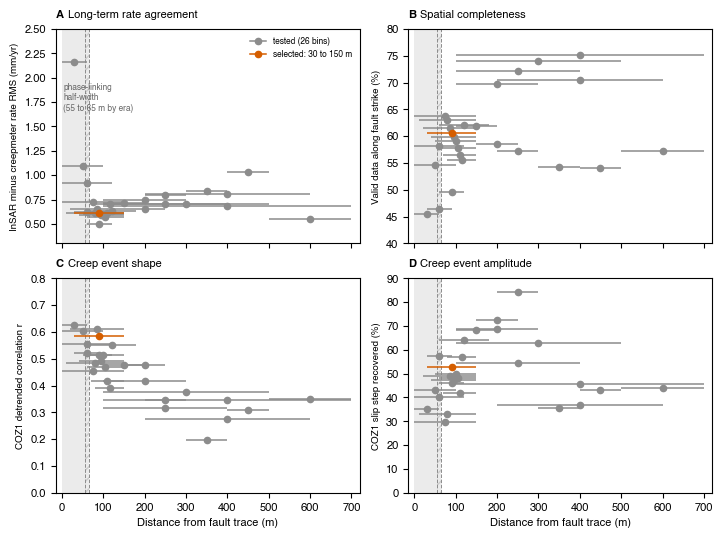

In [15]:
# [22]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True)
axes = axes.ravel()
is_selected = []
for bin_row in ladder.itertuples():
    is_selected.append((bin_row.inner, bin_row.outer) == selected)
ordered = ladder.assign(is_selected=is_selected).sort_values("is_selected")      # the selected bin drawn last, on top
selected_colour = "#D55E00"                                                      # Okabe-Ito vermillion


def panel_label(ax, letter, text, x=0.025, y=0.95, size=8.5):
    """Science style: bold capital, then the description in normal weight, one translucent box behind both."""
    # one wide box behind both pieces: drawn first on an invisible copy of the full string, then the two texts on top
    ax.text(x, y, f"{letter} {text}", transform=ax.transAxes, va="top", ha="left", fontsize=size, alpha=0,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7), zorder=5)
    letter_text = ax.text(x, y, letter, transform=ax.transAxes, va="top", ha="left", fontsize=size, fontweight="bold", zorder=6)
    ax.annotate(text, xy=(1, 1), xycoords=letter_text, xytext=(3, 0), textcoords="offset points", va="top", ha="left",
                fontsize=size, zorder=6)


def draw_ladder_scores(ax, score_column, scale=1.0):
    """One bar per bin (inner to outer edge) at the bin's score, a dot at the bin centre; the selected bin in colour."""
    for _, bin_row in ordered.iterrows():
        if not np.isfinite(bin_row[score_column]):
            continue
        score = scale * bin_row[score_column]
        if bin_row.is_selected:
            colour = selected_colour
            layer = 6
        else:
            colour = "0.55"
            layer = 2
        ax.plot([bin_row.inner, bin_row.outer], [score, score], "-", color=colour, lw=1.1, zorder=layer, solid_capstyle="butt")
        ax.plot(bin_row.centre, score, "o", ms=4.5, color=colour, zorder=layer + 1)


for ax in axes:
    ax.axvspan(0, kernel_m[0], facecolor="0.92", zorder=0)
    ax.axvspan(*kernel_m, facecolor="0.92", zorder=0, hatch="///", edgecolor="0.80", lw=0)
    for kernel_edge in kernel_m:
        ax.axvline(kernel_edge, color="0.55", lw=0.7, ls="--", zorder=1)
    ax.set_xlim(-15, 720)
axes[0].text(3, 1.95, f"phase-linking\nhalf-width\n({kernel_m[0]} to {kernel_m[1]} m by era)", fontsize=6, color="0.40", va="top")
ladder_panels = ((axes[0], "rate_rms", "InSAR minus creepmeter rate RMS (mm/yr)", (0.3, 2.5), "A", "Long-term rate agreement", 1),
                 (axes[1], "valid", "Valid data along fault strike (%)", (40, 80), "B", "Spatial completeness", 1),
                 (axes[2], "coz1_det_r", "COZ1 detrended correlation r", (0, 0.8), "C", "Creep event shape", 1),
                 (axes[3], "coz1_step_frac", "COZ1 slip step recovered (%)", (0, 90), "D", "Creep event amplitude", 100))
for ax, score_column, y_label, y_limits, letter, title, scale in ladder_panels:
    scores = scale * ladder[score_column].dropna()
    assert scores.between(*y_limits).all(), f"{score_column}: scores {scores.min():.2f} to {scores.max():.2f} fall outside the panel {y_limits}"
    draw_ladder_scores(ax, score_column, scale)
    ax.set_ylabel(y_label, fontsize=7)
    ax.set_ylim(*y_limits)
    panel_label(ax, letter, title, x=0.0, y=1.09, size=8)
for ax in axes[2:]:
    ax.set_xlabel("Distance from fault trace (m)")
axes[0].legend(handles=[Line2D([], [], color="0.55", lw=1.1, marker="o", ms=4.5, label=f"tested ({len(ladder)} bins)"),
                        Line2D([], [], color=selected_colour, lw=1.1, marker="o", ms=4.5, label=f"selected: {selected[0]} to {selected[1]} m")],
               fontsize=6, loc="upper right")
fig.tight_layout()
fig_lad = os.path.join(fig_dir, f"figS_binning_ladder_coh{ladder_coh:g}_mp{min_points}_stack{ladder_n_stack}x{ladder_stack_km}km.png")
fig.savefig(fig_lad, dpi=300)
fig.savefig(fig_lad.replace(".png", ".pdf"))
print("Saved figure to:", fig_lad)
plt.show()

## [23] REGISTER

The stats file `05_validation_stats.txt` (every table above) and the registry
rows `05_*` the paper quotes.

In [16]:
# [24]
stats_lines += ["", f"APERTURE LADDER (frozen sweep at coherence {ladder_coh}, fixed {ladder_n_stack}-row stack within {ladder_stack_km} km of latitude)",
                ladder.drop(columns=["tag"]).round(3).to_string(index=False), "",
                f"chosen bin {selected[0]}-{selected[1]} m by coherence threshold:", coh_table.round(3).to_string(index=False)]
sidecar = REG.sidecar("05_validation", stats_lines)
for code, station in stations.iterrows():
    for column_key, label in (("cm", "creepmeter"), ("cr", "crossing"), ("st", "step")):
        REG.register(f"05_{code}_{label}_rate_mm_yr", station[f"{column_key}_rate"], "mm/yr", 2, where="M4, Fig S validation", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{code}_{label}_ci_lo", station[f"{column_key}_lo"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{code}_{label}_ci_hi", station[f"{column_key}_hi"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{code}_det_r", station.det_r, "1", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{code}_det_rmse_mm", station.det_rmse, "mm", 2, where="M4", cell="bootstrap", sidecar=sidecar)
REG.register("05_rate_rms_mm_yr", agreement_stats["cross"]["rms"], "mm/yr", 2, where="P2, M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_bias_mm_yr", agreement_stats["cross"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_maxabs_mm_yr", agreement_stats["cross"]["maxabs"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_rms_excl_coz1_mm_yr", agreement_stats["cross_excl_coz1"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_rms_mm_yr", agreement_stats["step"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_bias_mm_yr", agreement_stats["step"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_noise_floor_det_rmse_mm", floor_rmse, "mm", 2, where="P2, M4", cell="noise-floor", sidecar=sidecar)
for _, window in cfw_windows.iterrows():
    onset_tag = f"{window.onset_lo:.2f}".replace(".", "p")             # key names kept: the window start, as before
    REG.register(f"05_cfw1_win_{onset_tag}_mm", window.slip_win_mm, "mm", 2, where="P3, Fig S validation", cell="cfw1-windows", sidecar=sidecar)
    REG.register(f"05_cfw1_win_{onset_tag}_expected_mm", window.expect_win_mm, "mm", 2, where="P3", cell="cfw1-windows", sidecar=sidecar)
    REG.register(f"05_cfw1_win_{onset_tag}_data_pct", window.cover_pct, "%", 0, where="P3", cell="cfw1-windows", sidecar=sidecar)
for creepmeter_code, (n_covered, n_matched) in gittins_counts.items():
    REG.register(f"05_gittins_{creepmeter_code.lower()}_windows_covered", n_covered, "count", 0, where="P3, M5", cell="gittins", sidecar=sidecar)
    REG.register(f"05_gittins_{creepmeter_code.lower()}_windows_matched", n_matched, "count", 0, where="P3, M5", cell="gittins", sidecar=sidecar)
REG.register("05_gittins_cfw1_n_events", len(background), "count", 0, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
REG.register("05_gittins_cfw1_rate_per_yr", cfw1_rate_per_yr, "1/yr", 1, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
REG.register("05_gittins_cfw1_median_slip_mm", cfw1_median_slip_mm, "mm", 2, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
REG.register("05_gittins_cfw1_catalogue_end", str(cfw1_end.date()), "date", 0, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
for year, (step_mm, n_crossings) in cfw1_insar_steps.items():
    REG.register(f"05_cfw1_insar_step_{year}_mm", step_mm, "mm", 1, where="P3, table Gittins", cell="cfw1-insar", sidecar=sidecar)
    REG.register(f"05_cfw1_insar_step_{year}_n", n_crossings, "count", 0, where="table Gittins", cell="cfw1-insar", sidecar=sidecar)
REG.register("05_cfw1_insar_step_sigma_mm", cfw1_insar_sigma, "mm", 1, where="P3, table Gittins", cell="cfw1-insar", sidecar=sidecar)
for event_id, step_mm in gittins_step.items():
    REG.register(f"05_cfw1_insar_step_gittins_{event_id.lower()}_mm", step_mm, "mm", 1, where="table Gittins", cell="cfw1-gittins-steps", sidecar=sidecar)
REG.register("05_cfw1_insar_step_gittins_sigma_mm", gittins_step_sigma, "mm", 1, where="table Gittins", cell="cfw1-gittins-steps", sidecar=sidecar)
REG.register("05_gittins_cfw1_window_pad_d", gittins_window_pad_days, "d", 0, where="table Gittins", cell="gittins-cfw1", sidecar=sidecar)
for label, pct in recovery_pct.items():
    REG.register(f"05_coz1_amp_recovery_{label}_pct", pct, "pct", 0, where="M4", cell="coz1-amplitude", sidecar=sidecar)
REG.register("05_coz1_amp_recovery_mean_pct", recovery_mean_pct, "pct", 0, where="M4", cell="coz1-amplitude", sidecar=sidecar)
REG.register("05_det_rmse_min_mm", stations.det_rmse.min(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_det_rmse_max_mm", stations.det_rmse.max(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_noise_floor_steady_std_mm", floor_steady_std, "mm", 2, where="M4 (alternative definition)", cell="noise-floor", sidecar=sidecar)
for _, coh_row in coh_table.iterrows():
    REG.register(f"05_coh{coh_row.coh:g}_rate_rms_mm_yr", coh_row.rate_rms, "mm/yr", 2, where="M3", cell="ladder", sidecar=sidecar)
    REG.register(f"05_coh{coh_row.coh:g}_n_crossings", int(coh_row.n_crossings), "count", 0, where="M3", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_n_bins", len(ladder), "count", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_rate_rms", selected_bin.rate_rms, "mm/yr", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_valid_pct", selected_bin.valid, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_det_r", selected_bin.coz1_det_r, "1", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_step_pct", 100 * selected_bin.coz1_step_frac, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/05_validation/05_validation_stats.txt
  registered 05_CPP1_creepmeter_rate_mm_yr = 5.05 mm/yr  -> M4, Fig S validation


  registered 05_CPP1_creepmeter_ci_lo = 4.95 mm/yr  -> M4
  registered 05_CPP1_creepmeter_ci_hi = 5.14 mm/yr  -> M4


  registered 05_CPP1_crossing_rate_mm_yr = 5.04 mm/yr  -> M4, Fig S validation
  registered 05_CPP1_crossing_ci_lo = 4.78 mm/yr  -> M4


  registered 05_CPP1_crossing_ci_hi = 5.32 mm/yr  -> M4
  registered 05_CPP1_step_rate_mm_yr = 3.65 mm/yr  -> M4, Fig S validation


  registered 05_CPP1_step_ci_lo = 2.48 mm/yr  -> M4
  registered 05_CPP1_step_ci_hi = 4.76 mm/yr  -> M4


  registered 05_CPP1_det_r = 0.27 1  -> M4
  registered 05_CPP1_det_rmse_mm = 1.79 mm  -> M4
  registered 05_CTM1_creepmeter_rate_mm_yr = 4.11 mm/yr  -> M4, Fig S validation
  registered 05_CTM1_creepmeter_ci_lo = 4.02 mm/yr  -> M4


... (25 outputs left out)

  registered 05_coh0.9_rate_rms_mm_yr = 0.63 mm/yr  -> M3
  registered 05_coh0.9_n_crossings = 480 count  -> M3
  registered 05_ladder_n_bins = 26 count  -> M3, Fig S ladder
  registered 05_ladder_selected_rate_rms = 0.61 mm/yr  -> M3, Fig S ladder


  registered 05_ladder_selected_valid_pct = 61 pct  -> M3, Fig S ladder
  registered 05_ladder_selected_coz1_det_r = 0.58 1  -> M3, Fig S ladder
  registered 05_ladder_selected_coz1_step_pct = 53 pct  -> M3, Fig S ladder


Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'